# Tuần 14 — Dự đoán (1/2): Đánh giá và cải thiện dự đoán

**UET.MAT1052 — Xác suất thống kê**

ThS. Hoàng Hữu Bách — BM. Khoa học & Kỹ thuật tính toán - Khoa Công nghệ Thông tin, VNU-UET

### Câu hỏi của buổi

Ở Tuần 04, ta đã khớp đường hồi quy cho quãng đường dừng xe theo tốc độ: $\hat y=-17{,}58+3{,}93x$, với $r=0{,}807$. Đường này có giá trị p rất nhỏ và $R^2=0{,}65$.

Như vậy đã đủ để dùng nó dự đoán chưa? Liên hệ ấy có thật trong tổng thể hay chỉ là dao động của mẫu 50 lần thử? Dự đoán sai khoảng bao nhiêu feet? Mô hình có vi phạm điều kiện nào không? Và khi có nhiều biến để chọn, nên giữ biến nào? Tuần này **đánh giá** rồi **cải thiện** một mô hình hồi quy trước khi dùng để dự đoán.

### Sau buổi này, bạn làm được

- khớp hồi quy bằng công thức bình phương tối thiểu và bằng thuật toán lặp (gradient descent); giải thích vì sao hai cách cho cùng kết quả;
- kiểm định hệ số tương quan $\rho$ và hệ số góc $\beta_1$ theo đủ 7 bước;
- tính và diễn giải $R^2$, RSE; nói rõ chúng đo mức khớp **trong mẫu**;
- đọc biểu đồ phần dư và Q-Q; phân biệt ngoại lai, điểm có leverage cao và điểm ảnh hưởng;
- tính VIF và giải thích nó phóng đại cái gì; chọn biến bằng $R^2$ hiệu chỉnh (loại trừ lùi, chọn tiến);
- diễn giải hệ số tương tác và quyết định khi nào giữ nó.

Nội dung đáp ứng **LLO14.1/CLO4** của đề cương.

### Cần nhớ từ các buổi trước

- **Hồi quy tuyến tính** (Tuần 04). $\hat y=b_0+b_1x$; phần dư $e_i=y_i-\hat y_i$; $b_1=r\, s_y/s_x$; biến chỉ báo cho biến phân loại.
- **Kiểm định $t$** (Tuần 10–11). Thống kê = (ước lượng − giá trị giả định) / SE; tra phân phối $t$ với bậc tự do phù hợp.
- **Dự đoán không phải nhân quả** (Tuần 12–13). Một hệ số dự đoán tốt chưa phải tác động của việc thay đổi biến đó.
- **Phương sai** (Tuần 07). $\mathrm{Var}(cY)=c^2\,\mathrm{Var}(Y)$; phương sai của tổng các biến độc lập bằng tổng phương sai.

### Cách học notebook này

1. **Đọc** tình huống và phần giải tay.
2. **Đoán** kết quả trước khi chạy ô code hay mở đáp án.
3. **Chạy** ô bằng `Shift + Enter`.
4. **So sánh** kết quả với dự đoán; nếu khác, tìm xem mình đã hiểu sai ở bước nào.

Khối **Vì sao?** chứa chứng minh, có thể đọc sau. Ô có chú thích **Thử đổi** là chỗ bạn sửa tham số rồi chạy lại. Tên Ví dụ, Bài và Câu hỏi giữ đúng như slide để tiện đối chiếu.

**Thực hành vẽ:** [hướng dẫn Plotnine](./HUONG_DAN_PLOT.md). Mỗi hình có một đoạn “Đọc code vẽ” giải thích đúng các lệnh dùng ở hình đó, và một đoạn “Đọc hình” chỉ ra cần nhìn vào đâu.

## Lộ trình học

| Cách học | Nội dung cần làm |
|---|---|
| Học trên lớp | Mục 1–4: khớp mô hình, kiểm định, $R^2$/RSE, chẩn đoán phần dư. Mục 5–7: VIF, chọn biến, tương tác. |
| Tự luyện | Bài tập 1–8 và Ví dụ 1–4: tính tay trước, đối chiếu output sau. Mục 8: đọc output và viết kết luận. |
| Đọc sâu | Gradient descent ở mục 1 (bổ sung theo LLO14.1); các khối **Vì sao?**: phương trình chuẩn, $T$ của $r$ bằng $T$ của $b_1$, $R^2=r^2$, công thức VIF. |

Chạy từ đầu bằng **Restart Kernel and Run All Cells** trước khi học, để mọi bảng và hình khớp với chữ trong bài.

### Đi đến các phần

[1. Nhắc lại mô hình để đánh giá đúng đối tượng](#muc-1) · [2. Kiểm định liên hệ tuyến tính](#muc-2) · [3. R² và RSE mô tả mức khớp trong mẫu](#muc-3) · [4. Phần dư, ngoại lai, đòn bẩy và ảnh hưởng](#muc-4) · [5. Nhiều biến dự đoán và VIF](#muc-5) · [6. Chọn biến: phạt độ phức tạp chưa thay được đánh giá ngoài mẫu](#muc-6) · [7. Tương tác cho độ dốc khác nhau](#muc-7) · [8. Đọc output và viết kết luận có giới hạn](#muc-8)

## Ký hiệu dùng trong buổi này

| Ký hiệu | Đọc là | Nghĩa | Ví dụ trong bài |
|---|---|---|---|
| $\beta_0$, $\beta_1$ | bê-ta không, bê-ta một | hệ số chặn và hệ số góc của **mô hình tổng thể** | $H_0:\beta_1=0$ |
| $b_0$, $b_1$ | b không, b một | hệ số ước lượng từ mẫu | $b_1\approx3{,}93$ feet/mph |
| $\rho$, $r$ | rô, r | hệ số tương quan tổng thể và mẫu | $r\approx0{,}807$ |
| $\hat y_i$, $e_i$ | y mũ i, e i | giá trị khớp (dự đoán) và phần dư $y_i-\hat y_i$ | $e_i>0$: điểm nằm trên đường |
| RSS, TSS |  | tổng bình phương phần dư; tổng bình phương độ lệch khỏi $\bar y$ | cars: RSS $\approx11\,354$, TSS $\approx32\,539$ |
| $R^2$ | R bình phương | tỉ lệ biến thiên của $y$ (trong mẫu) được mô hình giải thích | $0{,}651$ |
| RSE | residual standard error | độ lệch chuẩn ước lượng của sai số, cùng đơn vị với $y$ | $15{,}38$ feet |
| $p$ (hay $q$) | số biến dự đoán | số hệ số ngoài hệ số chặn | hồi quy đơn: $p=1$ |
| $R^2_{adj}$ | R bình phương hiệu chỉnh | $R^2$ có phạt số biến | stackloss: $0{,}898$ |
| $R_j^2$ | R bình phương j | $R^2$ khi hồi quy biến $x_j$ theo các biến dự đoán còn lại | air\_flow: $0{,}65$ |
| $\text{VIF}_j$ | hệ số phóng đại phương sai | $1/(1-R_j^2)$ | $1/0{,}35\approx2{,}86$ |

**Số biến dự đoán.** Slide viết $p$ cho số biến dự đoán trong $R^2_{adj}$; công thức RSE tổng quát là $\sqrt{\text{RSS}/(n-p-1)}$, với hồi quy đơn $p=1$ nên mẫu số $n-2$. Cẩn thận: chữ "p" trong "p-value" là chuyện khác.

**Cách viết.** $H_a$ (slide tuần này) là $H_1$ hay $H_A$ ở các tuần trước.

### Thiết lập tính toán

- `statsmodels.formula.api` (`smf`): `smf.ols('dist ~ speed', data).fit()` khớp hồi quy bằng công thức kiểu R; kết quả có `.params` (hệ số), `.bse` (SE), `.tvalues`, `.pvalues`, `.rsquared`, `.rsquared_adj`, `.resid`, `.fittedvalues`.
- `statsmodels.api` (`sm`): `sm.add_constant` thêm cột hằng số 1 (cần cho VIF ở mục 5).
- `DATA = Path('datasets')`: `cars.csv` (50 lần đo tốc độ, mph, và quãng đường dừng, feet) và `stackloss.csv` (21 quan sát vận hành nhà máy).
- Đây là dữ liệu lịch sử dùng để giảng dạy; không dùng mô hình làm quy tắc an toàn xe hay quy trình vận hành thực tế.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display

DATA = Path('datasets')
assert DATA.is_dir(), 'Hãy mở notebook từ thư mục có datasets/ đi kèm.'
rng = np.random.default_rng(42)
pd.set_option('display.precision', 5)
pd.set_option('display.max_columns', 12)

from plotnine import (ggplot, aes, geom_histogram, geom_line, geom_point, geom_col,
    geom_vline, geom_hline, geom_segment, geom_area, geom_tile, geom_text,
    facet_wrap, labs, theme_minimal, theme, element_text, scale_color_manual,
    scale_fill_manual, coord_cartesian)

<a id="muc-1"></a>

## 1. Nhắc lại mô hình để đánh giá đúng đối tượng

### Hai bộ dữ liệu

- `cars`: 50 lần thử, tốc độ `speed` (mph) và quãng đường dừng `dist` (feet). Dùng cho hồi quy đơn.
- `stackloss`: 21 quan sát vận hành nhà máy, với tỉ lệ thất thoát nguyên liệu `stack_loss` và ba biến vận hành `air_flow` (lưu lượng khí), `water_temp` (nhiệt độ nước), `acid_conc` (nồng độ axit). Dùng cho hồi quy nhiều biến.

### Bình phương tối thiểu

Hồi quy đơn chọn $b_0, b_1$ để **tổng bình phương phần dư** nhỏ nhất:
$$\text{RSS}(b_0, b_1)=\sum_{i=1}^n\big[y_i-(b_0+b_1x_i)\big]^2.$$
Khi $x$ không phải hằng số, nghiệm là
$$b_1=\frac{\sum_i(x_i-\bar x)(y_i-\bar y)}{\sum_i(x_i-\bar x)^2},\qquad b_0=\bar y-b_1\bar x.$$
Với `cars`: $\sum(x_i-\bar x)^2=1370$, $\sum(x_i-\bar x)(y_i-\bar y)=5387{,}4$, nên $b_1=5387{,}4/1370\approx3{,}932$ feet/mph và $b_0=42{,}98-3{,}932\times15{,}4\approx-17{,}58$ feet.
<details><summary><b>Vì sao?</b> công thức của $b_0$ và $b_1$</summary>

RSS là hàm bậc hai theo $b_0, b_1$, mở lên trên, nên cực tiểu ở chỗ hai đạo hàm riêng bằng 0.

*Theo $b_0$:* $\frac{\partial\text{RSS}}{\partial b_0}=-2\sum_i(y_i-b_0-b_1x_i)=0$, tức $\sum e_i=0$, nên $n\bar y=nb_0+b_1n\bar x$, hay $b_0=\bar y-b_1\bar x$. Hệ quả: đường hồi quy luôn đi qua điểm $(\bar x,\bar y)$.

*Theo $b_1$:* $\frac{\partial\text{RSS}}{\partial b_1}=-2\sum_i x_i(y_i-b_0-b_1x_i)=0$. Thay $b_0=\bar y-b_1\bar x$:
$$\sum_i x_i\big[(y_i-\bar y)-b_1(x_i-\bar x)\big]=0.$$
Vì $\sum(y_i-\bar y)=0$ và $\sum(x_i-\bar x)=0$, có thể thay $x_i$ bằng $x_i-\bar x$ ở thừa số đầu mà không đổi tổng. Do đó
$$b_1=\frac{\sum(x_i-\bar x)(y_i-\bar y)}{\sum(x_i-\bar x)^2}.\ \blacksquare$$
Hai phương trình này gọi là **phương trình chuẩn**; chúng nói phần dư có tổng bằng 0 và không tương quan với $x$.

</details>

Ô dưới đọc hai bộ dữ liệu, khớp `dist ~ speed` bằng statsmodels, rồi tính lại $b_0, b_1$ bằng công thức trên. `assert np.allclose(...)` báo lỗi nếu hai cách cho kết quả khác nhau.

In [2]:
cars=pd.read_csv(DATA/'cars.csv')
stack=pd.read_csv(DATA/'stackloss.csv')
display(cars.head());display(stack.head())
car_model=smf.ols('dist ~ speed',cars).fit()
x=cars.speed.to_numpy(); y=cars.dist.to_numpy()
b1=((x-x.mean())*(y-y.mean())).sum()/((x-x.mean())**2).sum()
b0=y.mean()-b1*x.mean()
print('Tính tay:',b0,b1,'; Statsmodels:',car_model.params.to_dict())
assert np.allclose([b0,b1],car_model.params)

,speed,dist
0,4,2
1,4,10
2,7,4
3,7,22
4,8,16


,stack_loss,air_flow,water_temp,acid_conc
0,42.0,80.0,27.0,89.0
1,37.0,80.0,27.0,88.0
2,37.0,75.0,25.0,90.0
3,28.0,62.0,24.0,87.0
4,18.0,62.0,22.0,87.0


Tính tay: -17.57909489051096 3.932408759124088 ; Statsmodels: {'Intercept': -17.57909489051096, 'speed': 3.9324087591240877}


### Bổ sung theo LLO14.1: tìm hệ số bằng thuật toán lặp

Khi mô hình phức tạp hơn (Tuần 15: hồi quy logistic), không còn công thức đóng; ta tìm hệ số bằng cách **đi dần xuống dốc** của hàm mất mát. Ở đây làm thử với hồi quy đơn để so với nghiệm đã biết.

**Hàm mất mát.** Sai số bình phương trung bình $\text{MSE}(b)=\frac1n\sum_i(\hat y_i-y_i)^2$, chính là RSS chia $n$. Viết gọn bằng ma trận $X$ (cột 1 toàn số 1, cột 2 là $x$) và vectơ hệ số $b$: $\hat y=Xb$.

**Gradient** (vectơ đạo hàm riêng) chỉ hướng MSE tăng nhanh nhất:
$$\nabla\text{MSE}(b)=\frac2n\, X^\top(Xb-y).$$

**Một bước lặp:** $b\leftarrow b-\eta\,\nabla\text{MSE}(b)$, với $\eta$ là **tốc độ học** (learning rate). Bắt đầu từ $b=(0,0)$ và lặp 250 lần.

**Chuẩn hóa $x$ trước.** Nếu để $x$ theo mph (4–25), hai hệ số có thang rất khác nhau và phải dùng $\eta$ rất nhỏ mới không phân kỳ. Đổi $x$ thành $(x-\bar x)/s_x$, chạy thuật toán, rồi đổi hệ số về đơn vị gốc: $b_1=\beta_1/s_x$, $b_0=\beta_0-b_1\bar x$.

**Bạn đoán trước:** sau 250 bước, hệ số có khớp với OLS đến bao nhiêu chữ số?

In [3]:
x_mean=x.mean(); x_sd=x.std(ddof=0)
X_std=np.column_stack([np.ones(len(x)),(x-x_mean)/x_sd])
beta=np.zeros(2)
learning_rate=.1  # Thử đổi .01, .5; theo dõi hội tụ trước khi tin hệ số
losses=[]
for step in range(250):
    residual=X_std@beta-y
    losses.append(np.mean(residual**2))
    gradient=2*X_std.T@residual/len(y)
    beta=beta-learning_rate*gradient
gd_slope=beta[1]/x_sd
gd_intercept=beta[0]-gd_slope*x_mean
print('Gradient descent:',gd_intercept,gd_slope,'; sai khác với OLS:',np.array([gd_intercept-b0,gd_slope-b1]))
loss_plot=pd.DataFrame({'step':np.arange(len(losses)),'mse':losses})
print('Đã hội tụ tới OLS trong sai số 1e-7:',np.allclose([gd_intercept,gd_slope],[b0,b1],atol=1e-7))

Gradient descent: -17.579094890510937 3.9324087591240855 ; sai khác với OLS: [ 2.13162821e-14 -2.66453526e-15]
Đã hội tụ tới OLS trong sai số 1e-7: True


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(loss_plot, aes(...))` lấy bảng `loss_plot`; trong `aes`, trục ngang là cột `step`, trục đứng là cột `mse`. `geom_line()` nối các điểm theo thứ tự tăng dần của trục ngang.

**Đọc hình.** MSE bắt đầu rất lớn (khoảng 2.500 feet², vì $b=(0,0)$ dự đoán 0 cho mọi xe), giảm nhanh trong vài chục bước đầu rồi nằm ngang ở khoảng 227 feet², đúng bằng RSS/$n$ của nghiệm OLS. Đường nằm ngang nghĩa là thuật toán đã hội tụ.

<!-- branch-plot-instructions: end -->

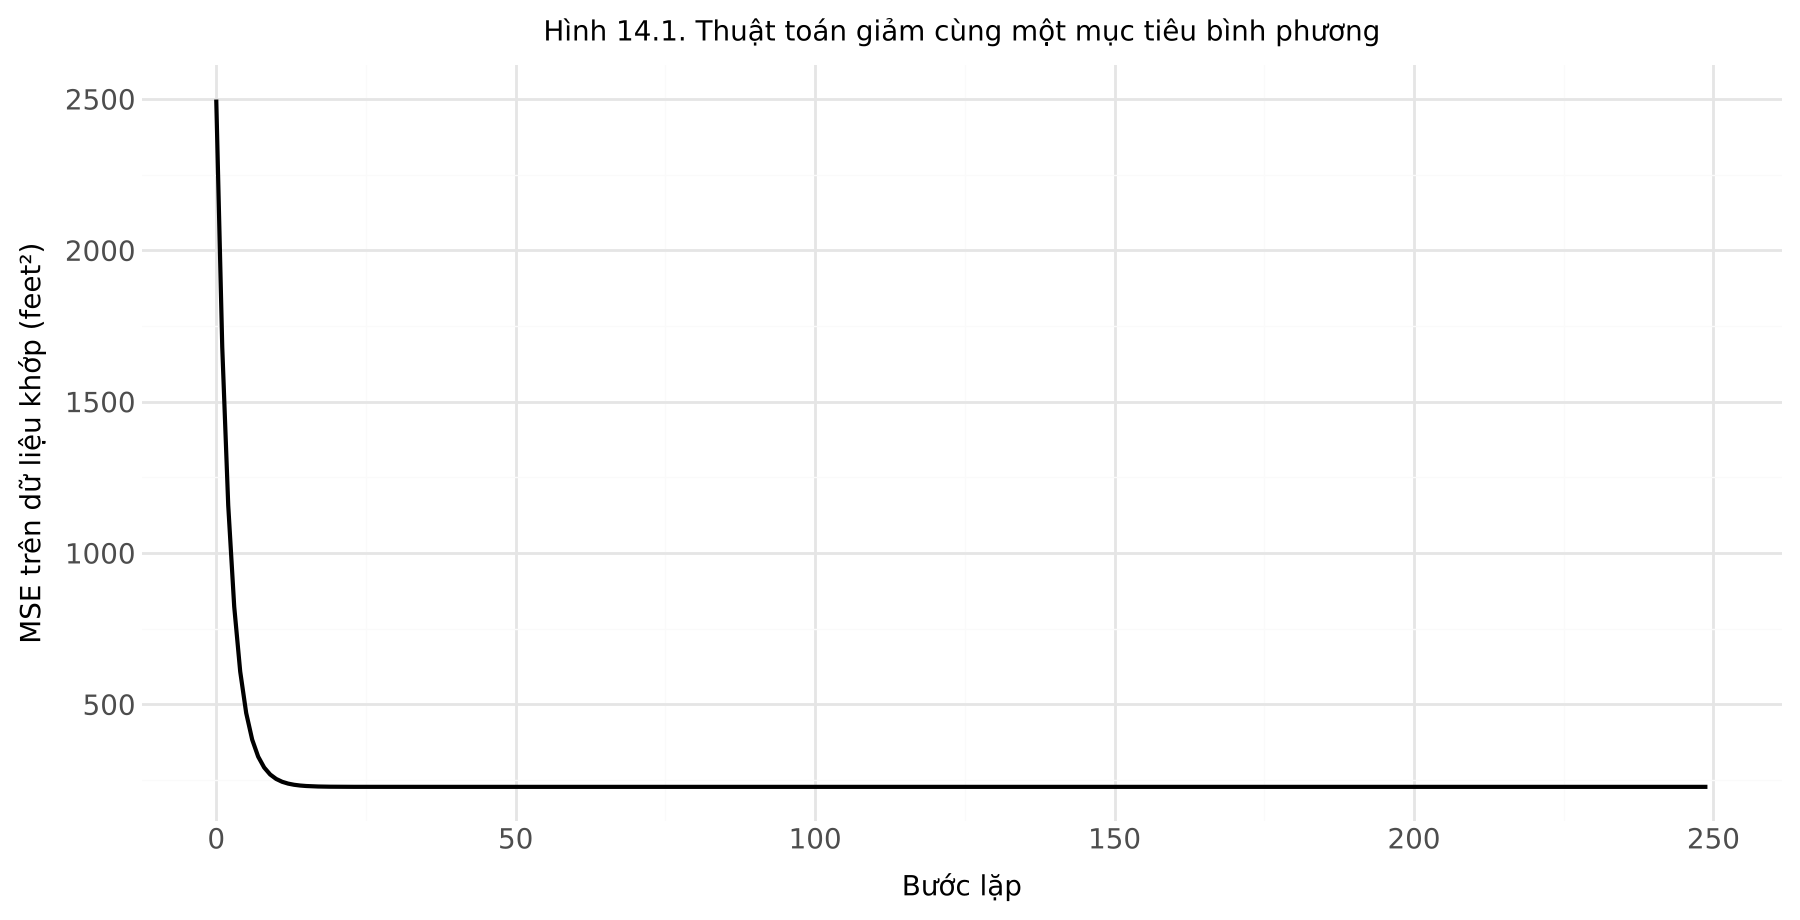

In [4]:
p = (ggplot(loss_plot, aes(x='step', y='mse'))
     + geom_line(size=0.85)
     + labs(title='Hình 14.1. Thuật toán giảm cùng một mục tiêu bình phương', x='Bước lặp', y='MSE trên dữ liệu khớp (feet²)')
     + theme_minimal()
     + theme(figure_size=(9, 4.6), text=element_text(size=10)))
display(p)

Sai khác với OLS chỉ cỡ $10^{-14}$: hai cách tối ưu **cùng một** hàm mục tiêu nên cho cùng nghiệm.

**Thử đổi.** `learning_rate = .01`: hội tụ chậm hơn nhiều, 250 bước có thể chưa đủ. `learning_rate = 1.1`: mỗi bước nhảy quá xa, MSE tăng vọt (phân kỳ). Luôn nhìn đường MSE trước khi tin hệ số.

MSE thấp trên **chính dữ liệu đã khớp** không nói gì về dự đoán trên dữ liệu mới; Tuần 15 sẽ quay lại điều này.

<a id="muc-2"></a>

## 2. Kiểm định liên hệ tuyến tính

$r=0{,}807$ và $b_1=3{,}93$ chỉ là ước lượng từ **một** mẫu 50 lần thử; mẫu khác sẽ cho số khác. Câu hỏi: liên hệ tuyến tính quan sát được có đủ mạnh để kết luận nó có trong tổng thể, hay chỉ là dao động ngẫu nhiên? Ta dùng quy trình kiểm định 7 bước của slide.

### Kiểm định hệ số tương quan

1. **Giả thuyết.** $H_0:\rho=0$ (không có liên hệ tuyến tính trong tổng thể), $H_a:\rho\ne0$. $\rho$ là tương quan tổng thể, chưa biết; $r$ là ước lượng.
2. **Mức ý nghĩa.** $\alpha=0{,}05$.
3. **Thống kê.**
$$T=\frac{r\sqrt{n-2}}{\sqrt{1-r^2}}.$$
Nếu $H_0$ đúng (và cặp $(x, y)$ là mẫu ngẫu nhiên từ phân phối chuẩn hai chiều), $T$ có phân phối $t_{n-2}$. $|r|$ càng lớn hoặc $n$ càng lớn thì $|T|$ càng lớn.
4. **Miền bác bỏ.** Hai phía: bác bỏ khi $|T|>t^*_{n-2,\,\alpha/2}$. Với `cars`, $n-2=48$, $t^*_{48,\,0{,}025}\approx2{,}011$.
5. **Tính.** $T=\dfrac{0{,}807\sqrt{48}}{\sqrt{1-0{,}807^2}}=\dfrac{0{,}807\times6{,}928}{0{,}591}\approx9{,}46$.
6. **Quyết định.** $9{,}46>2{,}011$: bác bỏ $H_0$; giá trị p $\approx1{,}5\times10^{-12}$.
7. **Kết luận.** Có bằng chứng thống kê rất mạnh về liên hệ tuyến tính giữa tốc độ và quãng đường dừng trong tổng thể, với điều kiện các giả định của mô hình phù hợp.

### Kiểm định hệ số góc

$H_0:\beta_1=0$ ($x$ không có liên hệ tuyến tính với $y$), $H_a:\beta_1\ne0$. Thống kê
$$T=\frac{b_1-0}{SE(b_1)},\qquad SE(b_1)=\sqrt{\frac{\hat\sigma^2}{\sum_i(x_i-\bar x)^2}},\qquad \hat\sigma^2=\frac{\text{RSS}}{n-2}.$$
Đọc là: hệ số góc ước lượng cách 0 bao nhiêu sai số chuẩn. Với `cars`: $\hat\sigma^2=11\,354/48\approx236{,}5$, $SE(b_1)=\sqrt{236{,}5/1370}\approx0{,}416$, $T=3{,}932/0{,}416\approx9{,}46$, cũng $df=48$.

### Hai kiểm định cho cùng một $T$

Trong hồi quy **đơn** có hệ số chặn, hai kiểm định luôn cho cùng $T$ và cùng giá trị p, vì chúng đo cùng một liên hệ, chỉ chuẩn hóa khác nhau ($b_1=r\, s_y/s_x$). Vì vậy phần mềm thường chỉ báo kiểm định cho $\beta_1$. Điều này **không** còn đúng nguyên xi với mô hình nhiều biến.

Mọi kiểm định ở đây dựa vào giả định $T$ có phân phối $t$: các sai số độc lập, phương sai không đổi, gần chuẩn. Mục 4 kiểm tra các điều kiện này.
<details><summary><b>Vì sao?</b> $T$ của $r$ bằng $T$ của $b_1$</summary>

Cần hai sự kiện của hồi quy đơn (chứng minh ở mục 3): $\text{RSS}=(1-r^2)\,\text{TSS}$ và $b_1=r\sqrt{\text{TSS}/S_{xx}}$, với $S_{xx}=\sum(x_i-\bar x)^2$, $\text{TSS}=\sum(y_i-\bar y)^2$.

Khi đó
$$SE(b_1)=\sqrt{\frac{\text{RSS}}{(n-2)S_{xx}}}=\sqrt{\frac{(1-r^2)\,\text{TSS}}{(n-2)\, S_{xx}}},$$
$$\frac{b_1}{SE(b_1)}=\frac{r\sqrt{\text{TSS}/S_{xx}}}{\sqrt{(1-r^2)\,\text{TSS}/\big((n-2)S_{xx}\big)}}=\frac{r\sqrt{n-2}}{\sqrt{1-r^2}}.\ \blacksquare$$

</details>

Ô dưới tính $T$ theo công thức của $r$, so với $T$ của hệ số góc trong output statsmodels, và dựng dữ liệu cho hình phân phối $t_{48}$ với miền bác bỏ.

In [5]:
r=cars.speed.corr(cars.dist); n=len(cars)
t_r=r*np.sqrt((n-2)/(1-r**2))
p_r=2*stats.t.sf(abs(t_r),n-2)
print('r:',r,'T:',t_r,'p:',p_r,'ngưỡng:',stats.t.ppf(.975,n-2))
print('Hệ số góc, SE, t, p:',car_model.params['speed'],car_model.bse['speed'],car_model.tvalues['speed'],car_model.pvalues['speed'])
assert np.isclose(t_r,car_model.tvalues['speed'])
t_grid=np.linspace(-11,11,1000)
t_plot=pd.DataFrame({'t':t_grid,'density':stats.t.pdf(t_grid,48),
    'region':np.where(np.abs(t_grid)>stats.t.ppf(.975,48),'Bác bỏ','Giữa')})

r: 0.8068949006892103 T: 9.463989990298366 p: 1.4898364962951035e-12 ngưỡng: 2.010634757624232
Hệ số góc, SE, t, p: 3.9324087591240877 0.41551277665712233 9.46398999029837 1.4898364962950807e-12


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(t_plot, aes(...))` lấy bảng `t_plot`; trong `aes`, trục ngang là cột `t`, trục đứng là cột `density`. `color='region'` cho mỗi giá trị của cột `region` một màu riêng. `geom_line()` nối các điểm theo thứ tự tăng dần của trục ngang. Cột phụ `_segment` tách từng đoạn liên tiếp của cùng một vùng, để hai phần đuôi không bị nối với nhau qua phần giữa; `geom_area` tô các vùng ở đuôi. `geom_vline(xintercept=...)` vẽ đường đứt đoạn tại `t_r`.

**Đọc hình.** Đường cong là phân phối của $T$ nếu $H_0$ đúng; gần như toàn bộ diện tích nằm trong khoảng ±3. Hai miền bác bỏ bắt đầu từ ±2,011. Đường đứt đoạn $T\approx9{,}46$ nằm rất xa bên phải, nơi đường cong đã sát 0.

<!-- branch-plot-instructions: end -->

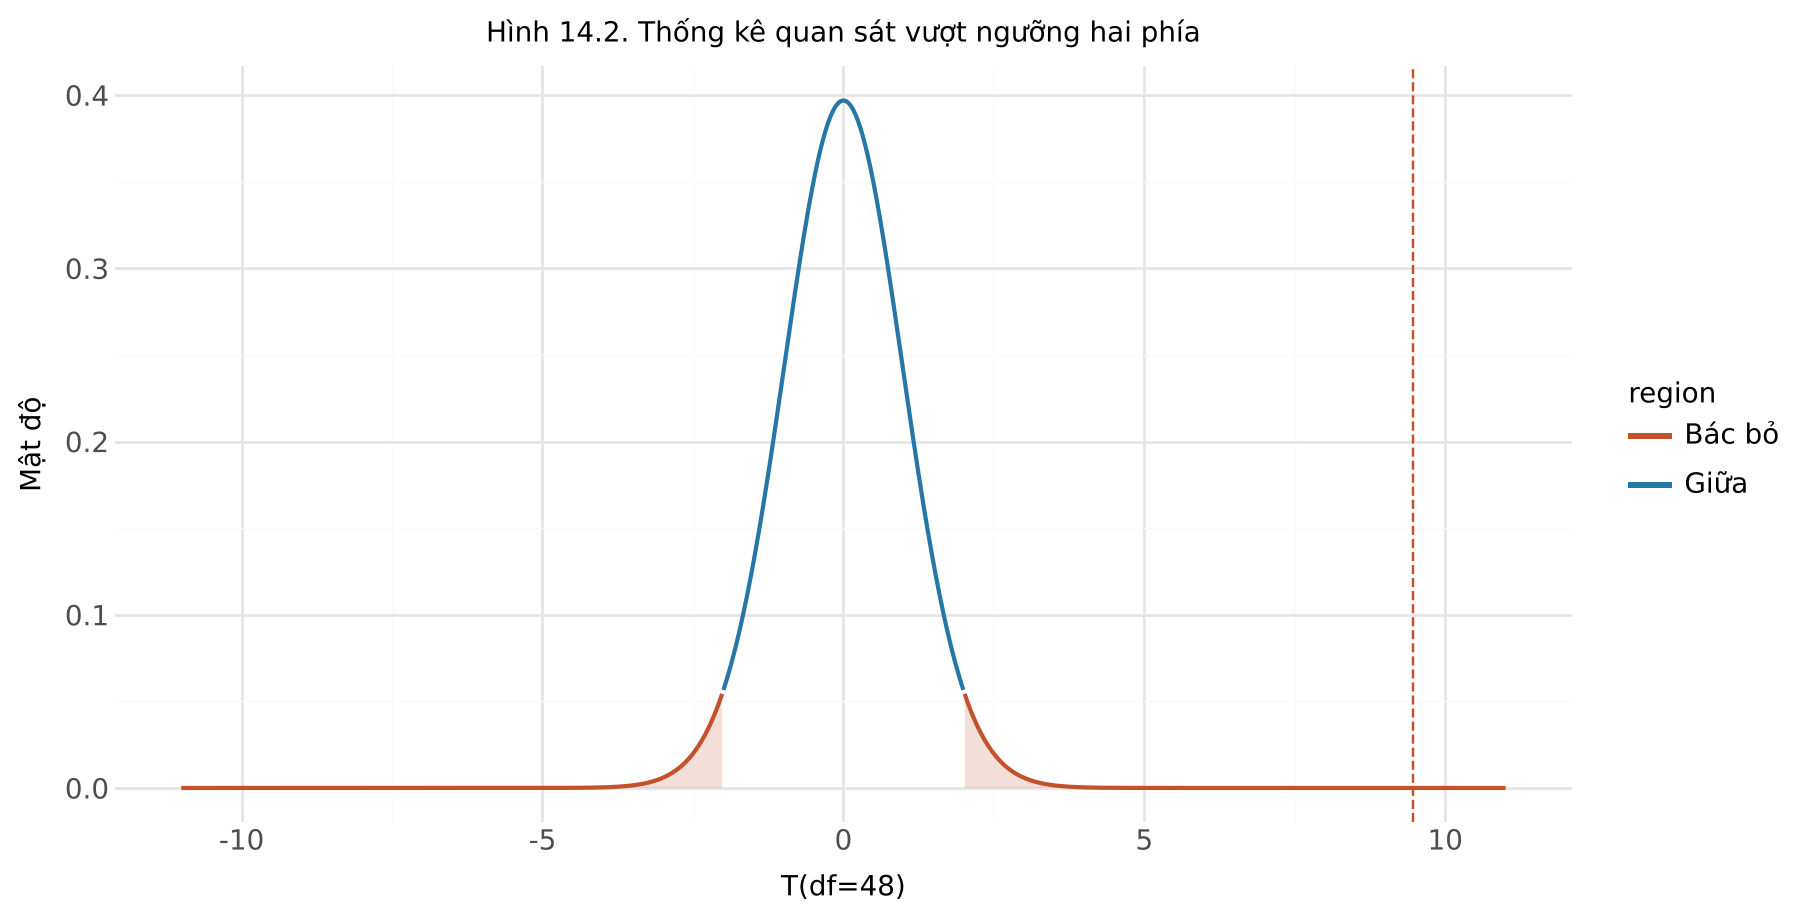

In [6]:
plot_data = t_plot.copy()
# Tách các đoạn liên tiếp để không nối hai đuôi qua phần giữa.
plot_data['_segment'] = plot_data['region'].ne(plot_data['region'].shift()).cumsum()
region_colors = {label: '#2677A6' if label in ['Giữa','Còn lại','Phần còn lại'] else '#C4512A' for label in pd.unique(plot_data.region)}
p = (ggplot(plot_data, aes(x='t', y='density', color='region', group='_segment'))
     + geom_line(size=0.85)
     + geom_area(aes(fill='region'), data=plot_data[~plot_data.region.isin(['Giữa','Còn lại','Phần còn lại'])], alpha=0.18, show_legend=False)
     + scale_color_manual(values=region_colors)
     + scale_fill_manual(values=region_colors)
     + geom_vline(xintercept=t_r, linetype='dashed', color='#C4512A')
     + labs(title='Hình 14.2. Thống kê quan sát vượt ngưỡng hai phía', x='T(df=48)', y='Mật độ')
     + theme_minimal()
     + theme(figure_size=(9, 4.6), text=element_text(size=10)))
display(p)

Hai cách cho cùng $T=9{,}464$. Ô dùng hệ số **đầy đủ chữ số**: lấy các số đã làm tròn $3{,}93/0{,}42$ sẽ ra $9{,}36$, khác $9{,}46$ chỉ vì làm tròn.

Kết luận "có bằng chứng rất mạnh" vẫn có điều kiện theo mô hình. Giá trị p nhỏ không có nghĩa "chắc chắn không do ngẫu nhiên", càng không có nghĩa tốc độ **gây ra** quãng đường dừng theo đúng hệ số 3,93 (dù ở đây điều đó hợp lý về vật lý, đó là hiểu biết ngoài dữ liệu).

### Bài tập 1 — Kiểm định hệ số tương quan cho một mẫu nhỏ

Một khảo sát $n=20$ cho $r=0{,}42$. Kiểm định $H_0:\rho=0$ với $\alpha=0{,}05$, làm đủ các bước: tính $T$, xác định miền bác bỏ, ra quyết định và kết luận.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Giả thuyết.* $H_0:\rho=0$, $H_a:\rho\ne0$; $\alpha=0{,}05$.

*Thống kê.*
$$T=\frac{0{,}42\sqrt{18}}{\sqrt{1-0{,}42^2}}=\frac{0{,}42\times4{,}243}{\sqrt{0{,}8236}}=\frac{1{,}782}{0{,}9075}\approx1{,}96.$$

*Miền bác bỏ.* $df=18$, $t^*_{18,\,0{,}025}\approx2{,}101$: bác bỏ khi $|T|>2{,}101$.

*Quyết định.* $1{,}96<2{,}101$: không bác bỏ $H_0$. Giá trị p $\approx0{,}065$.

*Kết luận.* Với mẫu 20 người này, chưa đủ bằng chứng thống kê ở mức 5% để khẳng định có liên hệ tuyến tính trong tổng thể. Không được nói "không có liên hệ": $r=0{,}42$ là khá lớn, nhưng 20 quan sát chưa đủ để phân biệt nó với 0. Với $n=30$ và cùng $r$, $T\approx2{,}44$ và ta sẽ bác bỏ.

</details>

### Bài tập 2 — Đọc bảng kết quả hồi quy

Một khảo sát khác ($n=20$) khớp mô hình `năng_suất ~ gio_tap` (số giờ luyện tập mỗi tuần và năng suất lao động):

| | Hệ số | Sai số chuẩn | t | Giá trị p |
|---|---|---|---|---|
| Hệ số chặn | 45,20 | 8,10 | 5,58 | <0,001 |
| gio_tap | 2,15 | 0,68 | 3,16 | 0,005 |

Ở mức 5%, hệ số góc của `gio_tap` có ý nghĩa thống kê không? Vì sao? Viết một câu diễn giải hệ số góc bằng lời, không dùng ký hiệu toán.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Ý nghĩa thống kê.* Có: giá trị p $=0{,}005<0{,}05$, nên bác bỏ $H_0:\beta_1=0$. Kiểm tra: $t=2{,}15/0{,}68\approx3{,}16$ như bảng.

*Diễn giải.* "Trong dữ liệu khảo sát, người luyện tập nhiều hơn 1 giờ mỗi tuần có năng suất dự đoán cao hơn trung bình khoảng 2,15 đơn vị."

Slide viết thêm "và đây không phải do ngẫu nhiên của mẫu". Câu này nên nói mềm hơn: giá trị p nhỏ cho thấy một hệ số góc như vậy **khó xảy ra** nếu thật ra không có liên hệ, chứ không loại trừ hoàn toàn khả năng ngẫu nhiên. Và đây là dữ liệu khảo sát, nên chưa suy ra được "tăng giờ luyện tập sẽ làm năng suất tăng 2,15" (người chăm luyện có thể khác ở nhiều mặt khác).

</details>

In [7]:
t_small=.42*np.sqrt(18/(1-.42**2))
print('Bài 1:',t_small,stats.t.ppf(.975,18),2*stats.t.sf(abs(t_small),18))
print('Bài 2, hệ số/SE làm tròn:',2.15/.68)

Bài 1: 1.9634840331218455 2.1009220402410382 0.06522885424080463
Bài 2, hệ số/SE làm tròn: 3.1617647058823524


<a id="muc-3"></a>

## 3. R² và RSE mô tả mức khớp trong mẫu

### Hai con số

$$R^2=1-\frac{\text{RSS}}{\text{TSS}},\qquad \text{TSS}=\sum_i(y_i-\bar y)^2,\qquad \text{RSE}=\sqrt{\frac{\text{RSS}}{n-p-1}}.$$

- **$R^2$**: tỉ lệ biến thiên của $y$ trong mẫu được mô hình giải thích. TSS là tổng bình phương sai số nếu chỉ dùng $\bar y$ để dự đoán; RSS là tổng bình phương sai số khi dùng mô hình. $R^2$ đo mô hình giảm được bao nhiêu phần so với cách đoán $\bar y$. Không có đơn vị.
- **RSE**: độ lớn sai số dự đoán điển hình, **cùng đơn vị với $y$**, thường dễ hình dung hơn. Hồi quy đơn có $p=1$, nên mẫu số là $n-2$.

Với `cars`: $R^2=1-11\,354/32\,539\approx0{,}651$: tốc độ giải thích khoảng 65% biến thiên quãng đường dừng **trong mẫu**. $\text{RSE}=\sqrt{11\,354/48}\approx15{,}38$ feet: dự đoán thường lệch cỡ 15 feet.

### $R^2=r^2$ trong hồi quy đơn

Với `cars`, $0{,}807^2=0{,}651$, đúng bằng $R^2$. Không phải trùng hợp: trong hồi quy đơn, hai con số đo cùng một liên hệ tuyến tính.
<details><summary><b>Vì sao?</b> $R^2=r^2$ và RSS $=(1-r^2)$TSS</summary>

Với $b_0=\bar y-b_1\bar x$, phần dư là $e_i=(y_i-\bar y)-b_1(x_i-\bar x)$. Đặt $S_{xx}=\sum(x_i-\bar x)^2$, $S_{xy}=\sum(x_i-\bar x)(y_i-\bar y)$ và nhớ $b_1=S_{xy}/S_{xx}$:
$$\text{RSS}=\text{TSS}-2b_1S_{xy}+b_1^2S_{xx}=\text{TSS}-\frac{S_{xy}^2}{S_{xx}}.$$
Vì $r=S_{xy}/\sqrt{S_{xx}\,\text{TSS}}$, nên $S_{xy}^2/S_{xx}=r^2\,\text{TSS}$, do đó
$$\text{RSS}=(1-r^2)\,\text{TSS},\qquad R^2=1-\frac{\text{RSS}}{\text{TSS}}=r^2.\ \blacksquare$$

</details>

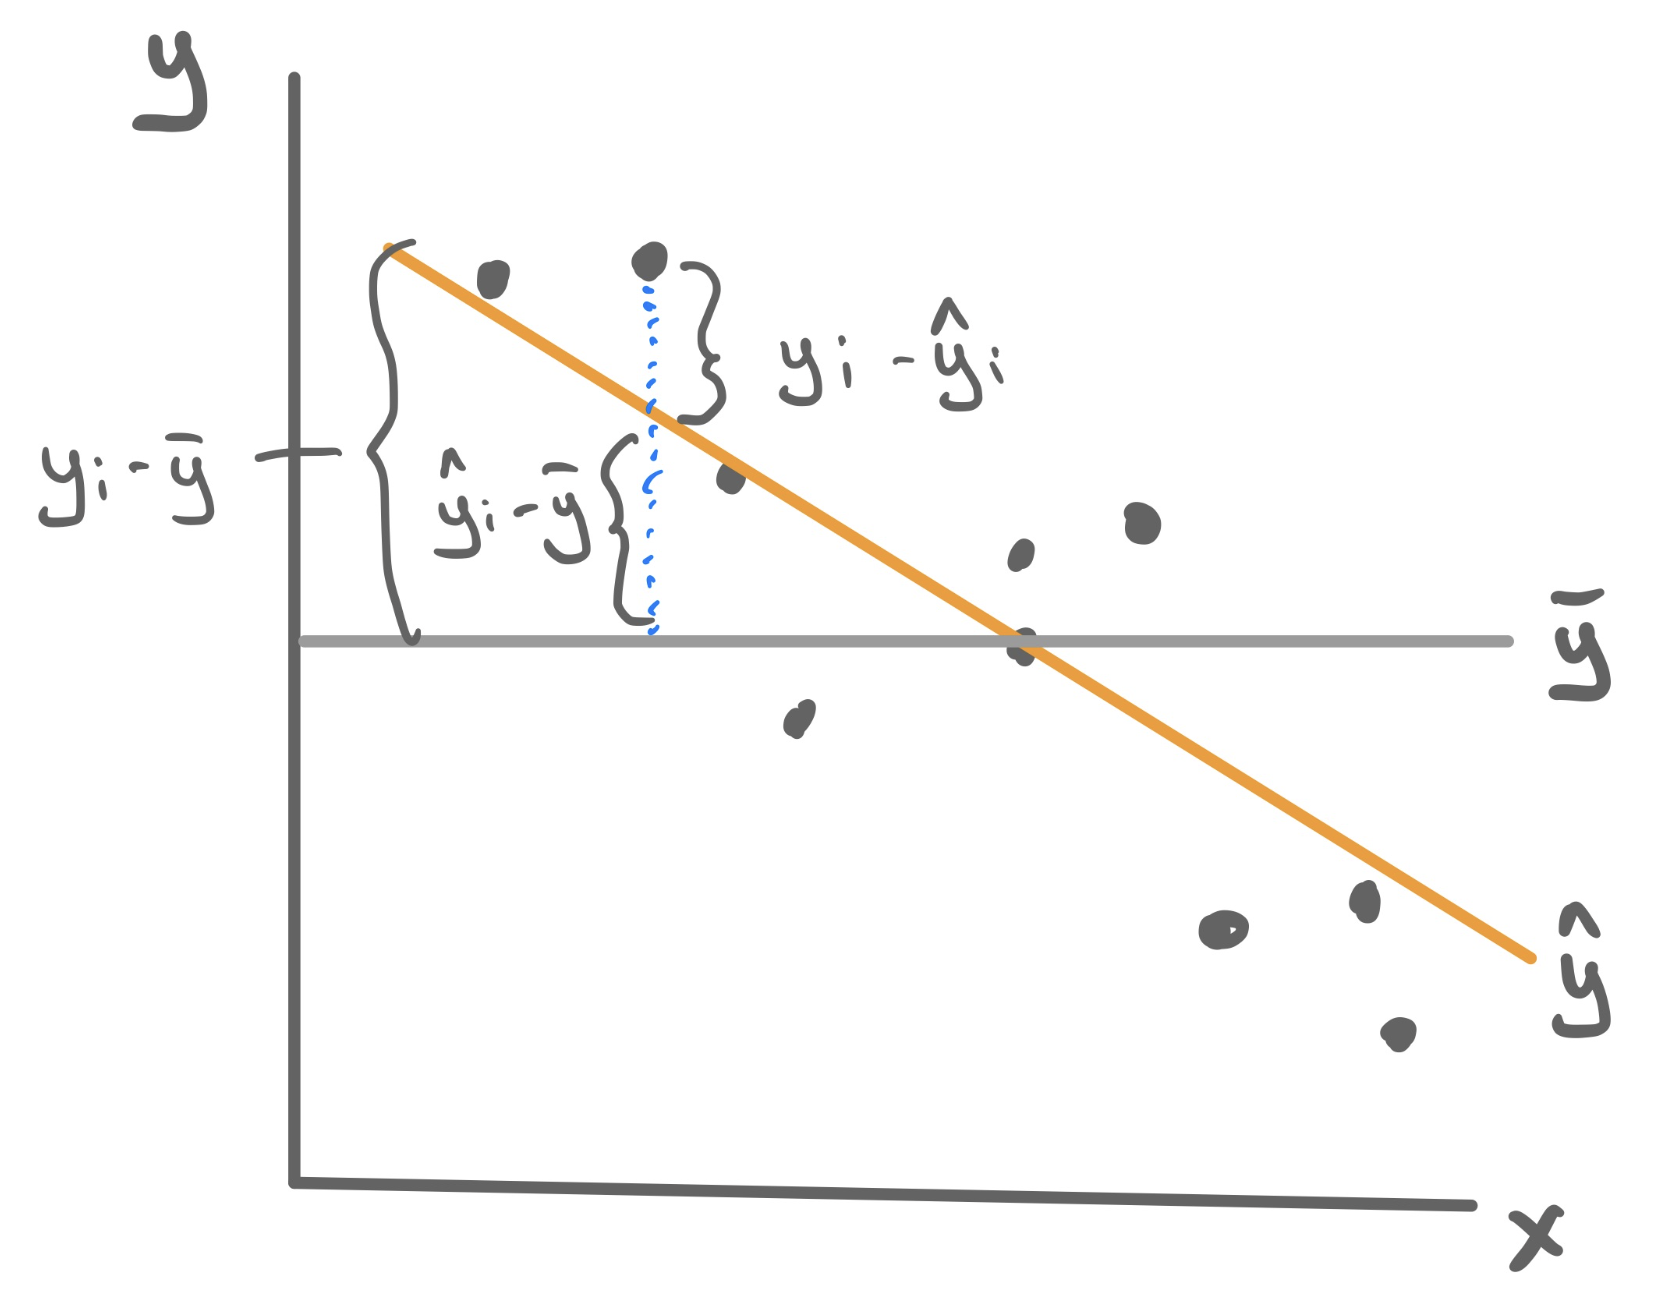

*Hình tham khảo 14.48: Phần dư là khoảng cách theo phương kết quả tới đường hồi quy. Nguồn: STAT 20 bản dịch tiếng Việt, mục 7.3, hình nhúng trong học liệu gốc.*

Mỗi đoạn thẳng đứng nối một điểm với đường hồi quy là một phần dư; RSS là tổng bình phương các đoạn này. Đây là khoảng cách theo trục $y$, không phải khoảng cách vuông góc từ điểm đến đường.

### Bài tập 3 — Tính R² và RSE từ RSS, TSS

Một mô hình khác (ví dụ độ thấm của đá theo diện tích lỗ rỗng) có RSS $=100$, TSS $=400$, $n=27$, hồi quy đơn có hệ số chặn. Tính $R^2$ và RSE, rồi diễn giải.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

$$R^2=1-\frac{100}{400}=0{,}75,\qquad \text{RSE}=\sqrt{\frac{100}{27-2}}=\sqrt4=2.$$
Mô hình giải thích 75% biến thiên của $y$ trong mẫu (theo nghĩa giảm tổng bình phương so với chỉ dùng trung bình). Sai số dự đoán điển hình khoảng 2 đơn vị của $y$.

Cả hai con số tính trên **dữ liệu đã dùng để khớp**; chúng chưa phải đánh giá trên dữ liệu mới.

</details>

Ô dưới tính $R^2$, RSE và thêm RMSE trong mẫu, $\sqrt{\text{RSS}/n}$, để thấy hai thước đo sai số khác nhau ở mẫu số ($n-2$ so với $n$).

In [8]:
rss=np.sum(car_model.resid**2); tss=np.sum((cars.dist-cars.dist.mean())**2)
rse=np.sqrt(rss/(len(cars)-2)); rmse=np.sqrt(rss/len(cars))
print('cars R²:',1-rss/tss,'RSE:',rse,'feet; RMSE trong mẫu:',rmse,'feet')
print('Bài 3:',1-100/400,np.sqrt(100/(27-2)))
assert np.isclose(car_model.rsquared,r*r)

cars R²: 0.6510793807582509 RSE: 15.379586748819907 feet; RMSE trong mẫu: 15.068855995791377 feet
Bài 3: 0.75 2.0


RSE $\approx15{,}38$ feet, RMSE trong mẫu $\approx15{,}07$ feet. Giá trị p của hệ số góc là $10^{-12}$, nhưng từng dự đoán vẫn có thể lệch 15–30 feet. Ý nghĩa thống kê của liên hệ và độ chính xác của từng dự đoán là hai chuyện khác nhau.

### Giới hạn của $R^2$

- $R^2$ cao **không chứng minh** dạng hàm đúng: liên hệ thật có thể cong mà $R^2$ tuyến tính vẫn cao.
- $R^2$ và RSE tính trên **chính dữ liệu đã khớp**: chúng đo mức khớp trong mẫu, không đo khả năng dự đoán trên dữ liệu chưa từng thấy.
- Thêm biến vào mô hình (trên cùng dữ liệu) **không bao giờ làm $R^2$ giảm**, kể cả biến vô dụng: mô hình nhiều biến luôn khớp được ít nhất tốt như mô hình ít biến. Vì vậy không dùng $R^2$ để so mô hình khác số biến; mục 6 dùng $R^2$ hiệu chỉnh.

$R^2$ cao trên dữ liệu huấn luyện chưa phải dự đoán tốt trên dữ liệu mới. Đó là chủ đề "quá khớp" của Tuần 15.

<a id="muc-4"></a>

## 4. Phần dư, ngoại lai, đòn bẩy và ảnh hưởng

### Bốn điều kiện của mô hình

Ba điều kiện đầu đọc được từ biểu đồ phần dư:

1. **Tuyến tính**: xu hướng giữa $x$ và $y$ gần đường thẳng. Nếu dữ liệu cong rõ, cần mô hình khác.
2. **Phần dư gần chuẩn**: vi phạm thường do ngoại lai hoặc điểm ảnh hưởng mạnh.
3. **Phương sai không đổi**: độ phân tán của phần dư ổn định dọc theo $x$, không phình to dần ("hình loa kèn").

Điều kiện thứ tư không đọc được từ đồ thị:

4. **Quan sát độc lập**: cần biết dữ liệu được thu thế nào. Cẩn thận với dữ liệu theo thời gian (giá cổ phiếu từng ngày) hay theo cụm (Tuần 13).

Bốn điều kiện này là nền tảng để tin **cả** vào dự đoán **lẫn** vào các kiểm định ở mục 2. Riêng điều kiện chuẩn chủ yếu phục vụ kiểm định $t$ và khoảng tin cậy chính xác; OLS vẫn tính được hệ số khi sai số không chuẩn.

### Biểu đồ phần dư theo giá trị khớp

Vẽ $e_i$ theo $\hat y_i$ giống như "lật ngang" biểu đồ phân tán sao cho đường hồi quy nằm ngang ở 0, giúp nhìn rõ vi phạm hơn.

- Phân tán đều quanh 0, không có khuôn mẫu: tuyến tính và phương sai không đổi hợp lý.
- Khuôn mẫu cong: dấu hiệu vi phạm tuyến tính.
- Hình loa kèn mở rộng dần: dấu hiệu vi phạm phương sai không đổi.

**Biểu đồ Q-Q** đối chiếu phần dư đã sắp thứ tự với phân vị của phân phối chuẩn. Nếu phần dư gần chuẩn, các điểm nằm gần một đường thẳng.

### Ngoại lai, leverage, điểm ảnh hưởng

- **Ngoại lai** (outlier) trong hồi quy: quan sát nằm xa đám mây các điểm còn lại, theo trục $x$, trục $y$, hoặc cả hai. Ngoại lai theo $y$ có phần dư lớn.
- **Leverage cao** (đòn bẩy): điểm có giá trị $x$ xa phần lớn dữ liệu. Về hình học, nó có "cánh tay đòn" dài, dễ kéo đường hồi quy về phía mình. Leverage chỉ phụ thuộc $x$.
- **Điểm ảnh hưởng** (influential point): điểm mà nếu bỏ đi thì đường hồi quy thay đổi đáng kể. Leverage cao chưa chắc gây ảnh hưởng lớn, nếu điểm đó vẫn nằm đúng xu hướng chung. Cách kiểm tra nhanh: khớp lại không có điểm đó, so hệ số góc. Chỉ số **khoảng cách Cook** gộp cả leverage và phần dư thành một con số.

### Xử lý ngoại lai

Không xóa một điểm chỉ vì nó "trông lạ" hay vì bỏ đi thì giá trị p đẹp hơn. Ngoại lai có thể phản ánh một hiện tượng thật đáng chú ý. Chỉ loại khi có bằng chứng cụ thể (nhập sai, đo sai, sai đối tượng), và phải báo cáo rõ đã loại điểm nào, vì sao.

Ô dưới chuẩn bị dữ liệu cho hai biểu đồ chẩn đoán và in 5 quan sát có khoảng cách Cook lớn nhất.

- `stats.probplot(..., fit=False)` trả về phân vị chuẩn lý thuyết và phần dư đã sắp thứ tự.
- `car_model.get_influence()` cho các chỉ số ảnh hưởng: `hat_matrix_diag` là leverage, `resid_studentized_internal` là phần dư đã chuẩn hóa, `cooks_distance[0]` là khoảng cách Cook.

In [9]:
diagnostic=pd.DataFrame({'fitted':car_model.fittedvalues,'residual':car_model.resid})
theoretical,ordered=stats.probplot(car_model.resid,dist='norm',fit=False)
qq=pd.DataFrame({'theoretical':theoretical,'residual':ordered})
influence=car_model.get_influence()
display(pd.DataFrame({'leverage':influence.hat_matrix_diag,
    'studentized_residual':influence.resid_studentized_internal,
    'Cook_distance':influence.cooks_distance[0]}).sort_values('Cook_distance',ascending=False).head())

,leverage,studentized_residual,Cook_distance
48,0.07399,2.91906,0.34040
22,0.02143,2.79517,0.08555
38,0.03545,-1.92452,0.06805
44,0.06216,-1.26671,0.05318
34,0.02493,2.02782,0.05258


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(diagnostic, aes(...))` lấy bảng `diagnostic`; trong `aes`, trục ngang là cột `fitted`, trục đứng là cột `residual`. `geom_point()` vẽ mỗi dòng của bảng thành một chấm.

**Đọc hình.** Các điểm rải quanh 0, không thấy hình cong rõ. Ở bên phải (giá trị khớp lớn, tức tốc độ cao), độ phân tán hơi rộng hơn bên trái, và có vài điểm phần dư +40 đến +45 feet. Đó là dấu hiệu nhẹ của phương sai tăng theo tốc độ, chưa phải hình loa kèn rõ.

<!-- branch-plot-instructions: end -->

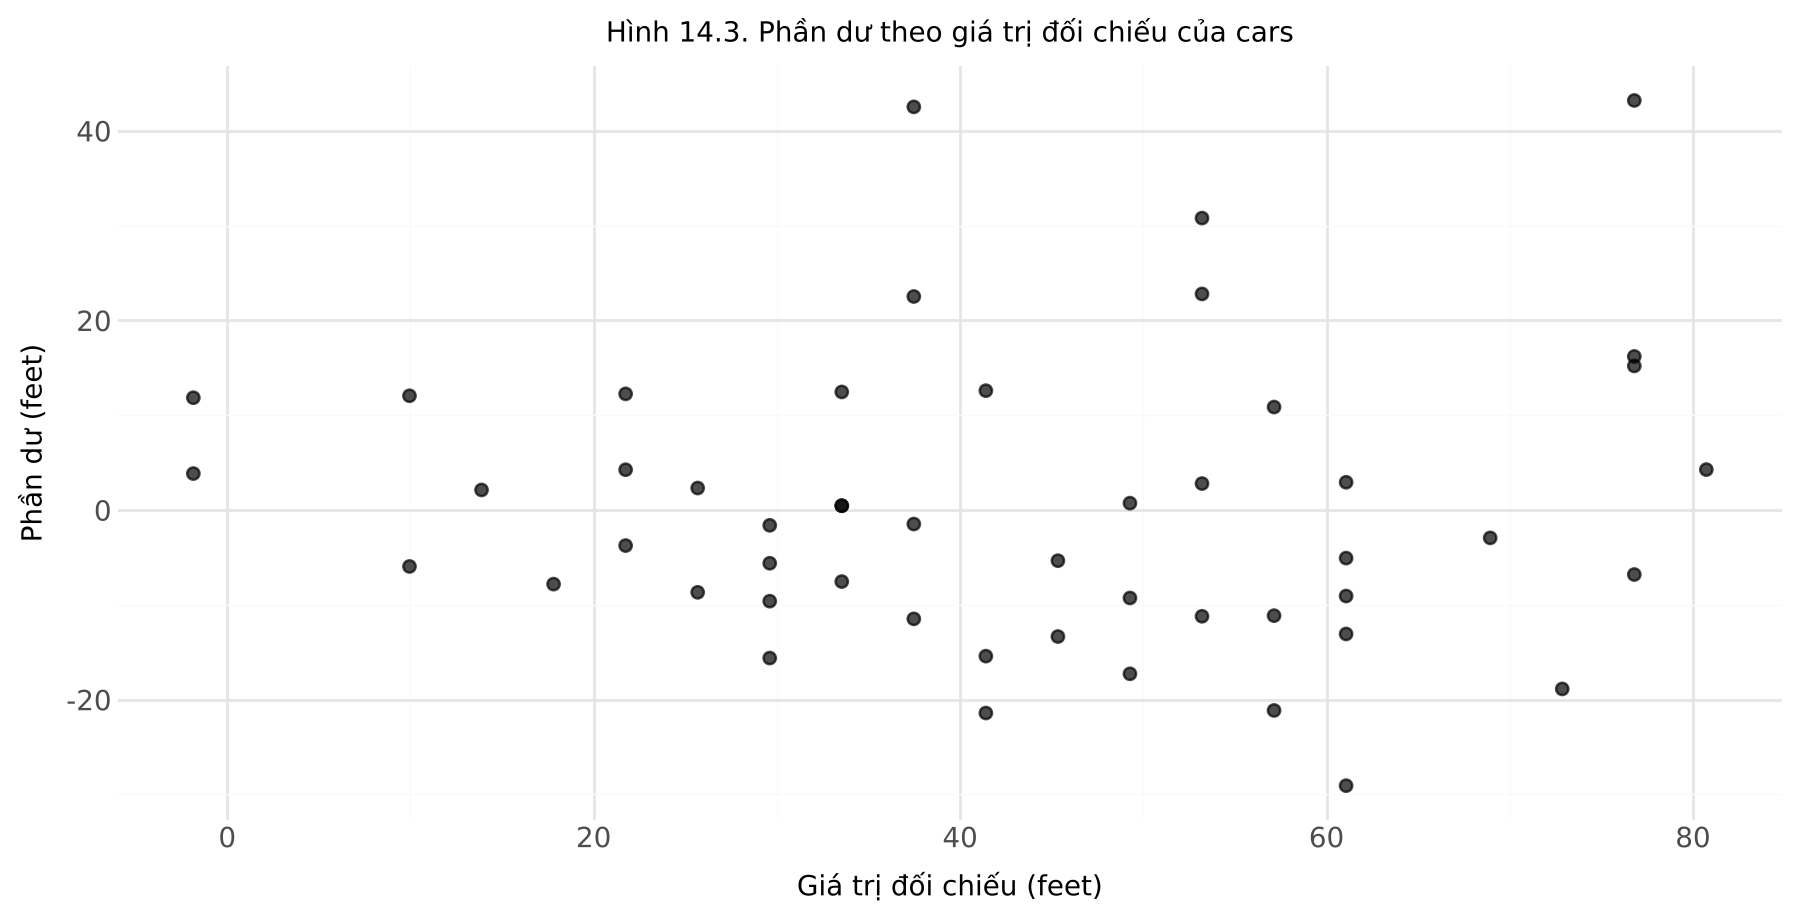

In [10]:
p = (ggplot(diagnostic, aes(x='fitted', y='residual'))
     + geom_point(alpha=0.7, size=2)
     + labs(title='Hình 14.3. Phần dư theo giá trị đối chiếu của cars', x='Giá trị đối chiếu (feet)', y='Phần dư (feet)')
     + theme_minimal()
     + theme(figure_size=(9, 4.6), text=element_text(size=10)))
display(p)

Slide kết luận: không có khuôn mẫu cong rõ, không có vi phạm nghiêm trọng. Bảng trên cho thấy quan sát số 48 (chỉ số 0) có khoảng cách Cook lớn nhất, 0,34: tốc độ 24 mph, phần dư lớn (phần dư chuẩn hóa 2,9). Đáng xem lại, nhưng chưa phải lý do để xóa.

Đồ thị phần dư đẹp cũng không nói gì về việc 50 lần thử có độc lập không; điều đó phụ thuộc cách thu dữ liệu.

<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(qq, aes(...))` lấy bảng `qq`; trong `aes`, trục ngang là cột `theoretical`, trục đứng là cột `residual`. `geom_point()` vẽ mỗi dòng của bảng thành một chấm.

**Đọc hình.** Phần giữa bám khá sát một đường thẳng. Ở đầu phải, vài điểm cao hơn đường: phần dư dương lớn nhiều hơn chuẩn dự kiến, tức đuôi phải hơi dày. Đường thẳng tham chiếu không phải $y=x$, vì phần dư tính bằng feet còn phân vị chuẩn không có đơn vị.

<!-- branch-plot-instructions: end -->

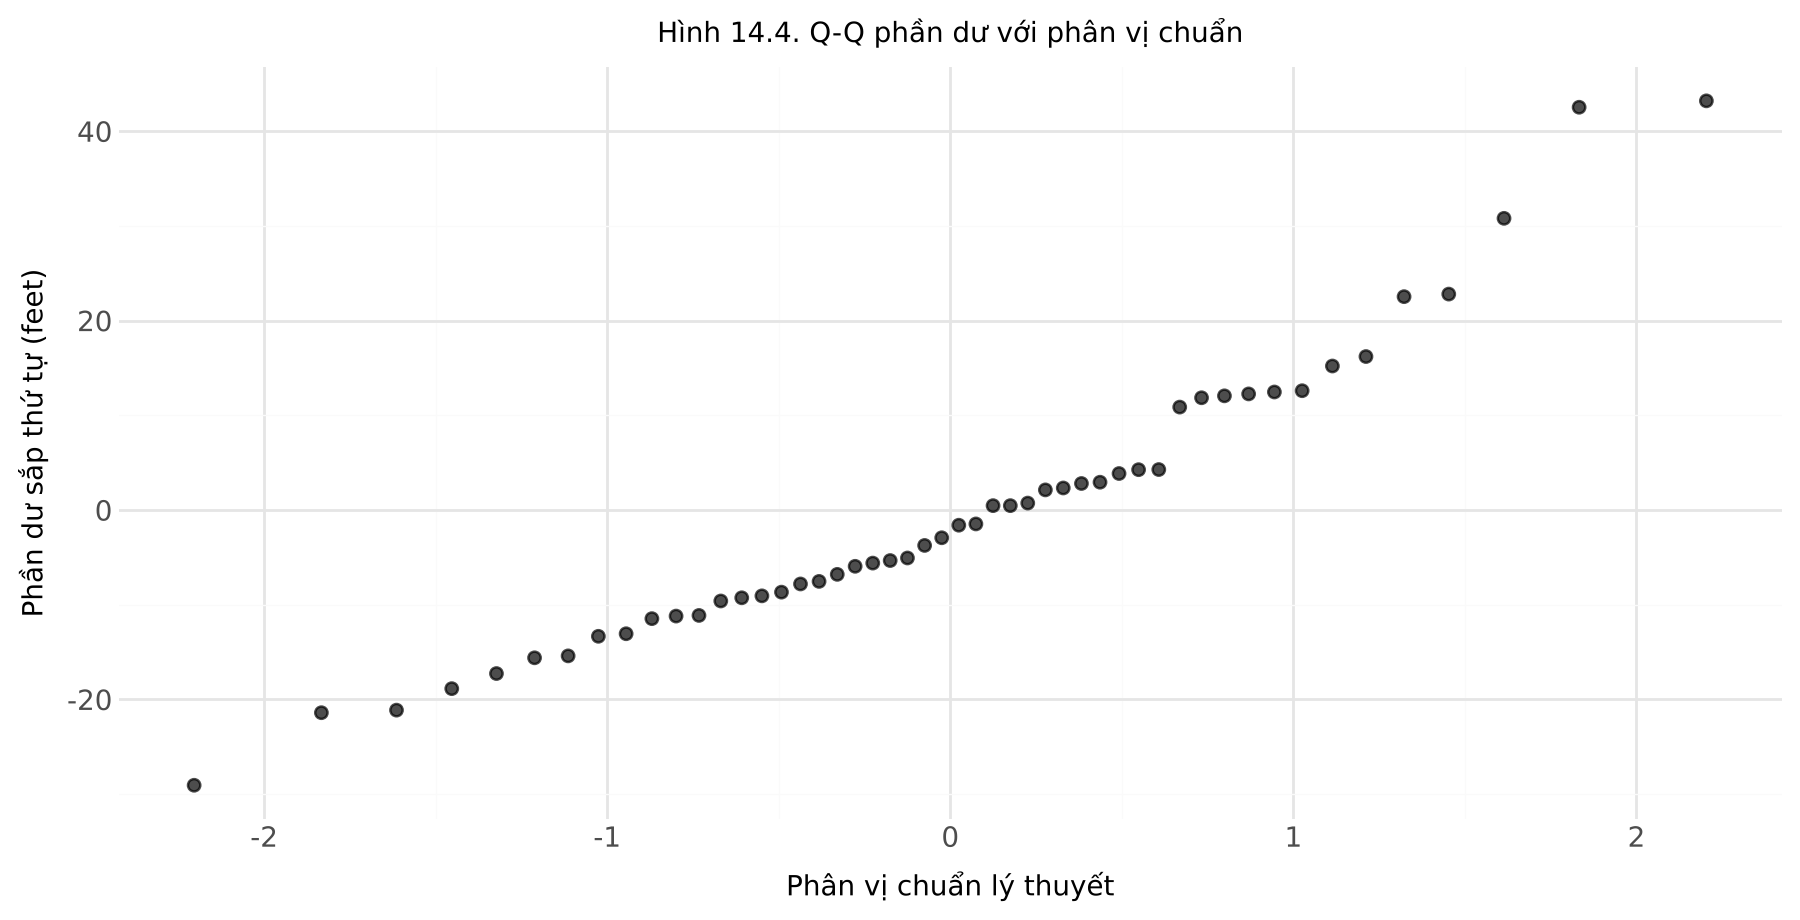

In [11]:
p = (ggplot(qq, aes(x='theoretical', y='residual'))
     + geom_point(alpha=0.7, size=2)
     + labs(title='Hình 14.4. Q-Q phần dư với phân vị chuẩn', x='Phân vị chuẩn lý thuyết', y='Phần dư sắp thứ tự (feet)')
     + theme_minimal()
     + theme(figure_size=(9, 4.6), text=element_text(size=10)))
display(p)

Đánh giá bằng mắt không có ranh giới chắc chắn. Với 50 điểm, độ lệch nhẹ ở đuôi như vậy thường không đáng lo cho kiểm định $t$ của hệ số góc.

### Ví dụ 1 — Điểm có leverage cao

Giả sử `cars` có thêm một lần thử ở tốc độ 45 mph, trong khi các lần khác chỉ từ 4 đến 25 mph. Đây là điểm có leverage cao. Nó có chắc chắn là điểm ảnh hưởng mạnh không?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

Không chắc. Leverage cao do **vị trí $x$** xa dữ liệu; ảnh hưởng còn tùy **$y$** của điểm đó.

- Nếu quãng đường dừng đo được ở 45 mph **nằm đúng** xu hướng tuyến tính cũ, điểm có leverage cao nhưng ít ảnh hưởng: đường hồi quy gần như không đổi.
- Nếu nó **lệch xa** đường cũ, điểm vừa có leverage cao vừa ảnh hưởng mạnh: nó kéo lệch hẳn đường hồi quy về phía mình.

Muốn biết, phải khớp lại và so hệ số. Không xóa điểm chỉ vì nó xa.

</details>

Ô dưới thử hai kịch bản cho điểm $x=45$: (1) $y$ đúng bằng dự đoán của đường cũ; (2) $y$ thấp hơn dự đoán 130 feet. Mỗi kịch bản khớp lại mô hình trên 51 điểm và ghi hệ số góc mới, leverage của điểm mới.

**Bạn đoán trước:** leverage của điểm mới ở hai kịch bản có khác nhau không?

In [12]:
x_new=45
old_prediction=b0+b1*x_new
sensitivity=[]; fitted_lines=[]
grid_speed=np.linspace(4,45,100)
for scenario,y_new in [('Trên đường cũ',old_prediction),('Lệch xa đường',old_prediction-130)]:
    extended=pd.concat([cars,pd.DataFrame({'speed':[x_new],'dist':[y_new]})],ignore_index=True)
    m=smf.ols('dist ~ speed',extended).fit()
    sensitivity.append([scenario,m.params['speed'],m.get_influence().hat_matrix_diag[-1]])
    fitted_lines.append(pd.DataFrame({'speed':grid_speed,'prediction':m.predict(pd.DataFrame({'speed':grid_speed})),
        'scenario':scenario,'model':'Có điểm mới'}))
    fitted_lines.append(pd.DataFrame({'speed':grid_speed,'prediction':b0+b1*grid_speed,
        'scenario':scenario,'model':'Đường cũ'}))
sensitivity_lines=pd.concat(fitted_lines,ignore_index=True)
display(pd.DataFrame(sensitivity,columns=['Tình huống','Hệ số góc mới','Leverage điểm mới']))

,Tình huống,Hệ số góc mới,Leverage điểm mới
0,Trên đường cũ,3.93241,0.39742
1,Lệch xa đường,2.23991,0.39742


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(sensitivity_lines, aes(...))` lấy bảng `sensitivity_lines`; trong `aes`, trục ngang là cột `speed`, trục đứng là cột `prediction`. `color='model'` cho mỗi giá trị của cột `model` một màu riêng. `geom_line()` nối các điểm theo thứ tự tăng dần của trục ngang. `facet_wrap('~scenario', scales='free')` vẽ mỗi giá trị của `scenario` vào một ô riêng; `scales='free'` cho mỗi ô thang trục riêng, nên so các ô bằng số ghi trên trục, không bằng độ cao trên màn hình.

**Đọc hình.** Mỗi ô có hai đường: đường cũ (50 điểm) và đường khớp lại sau khi thêm điểm $x=45$. Ô “Trên đường cũ”: hai đường trùng nhau. Ô “Lệch xa đường”: đường mới dốc thoải hơn hẳn và lệch nhiều ở tốc độ cao.

<!-- branch-plot-instructions: end -->

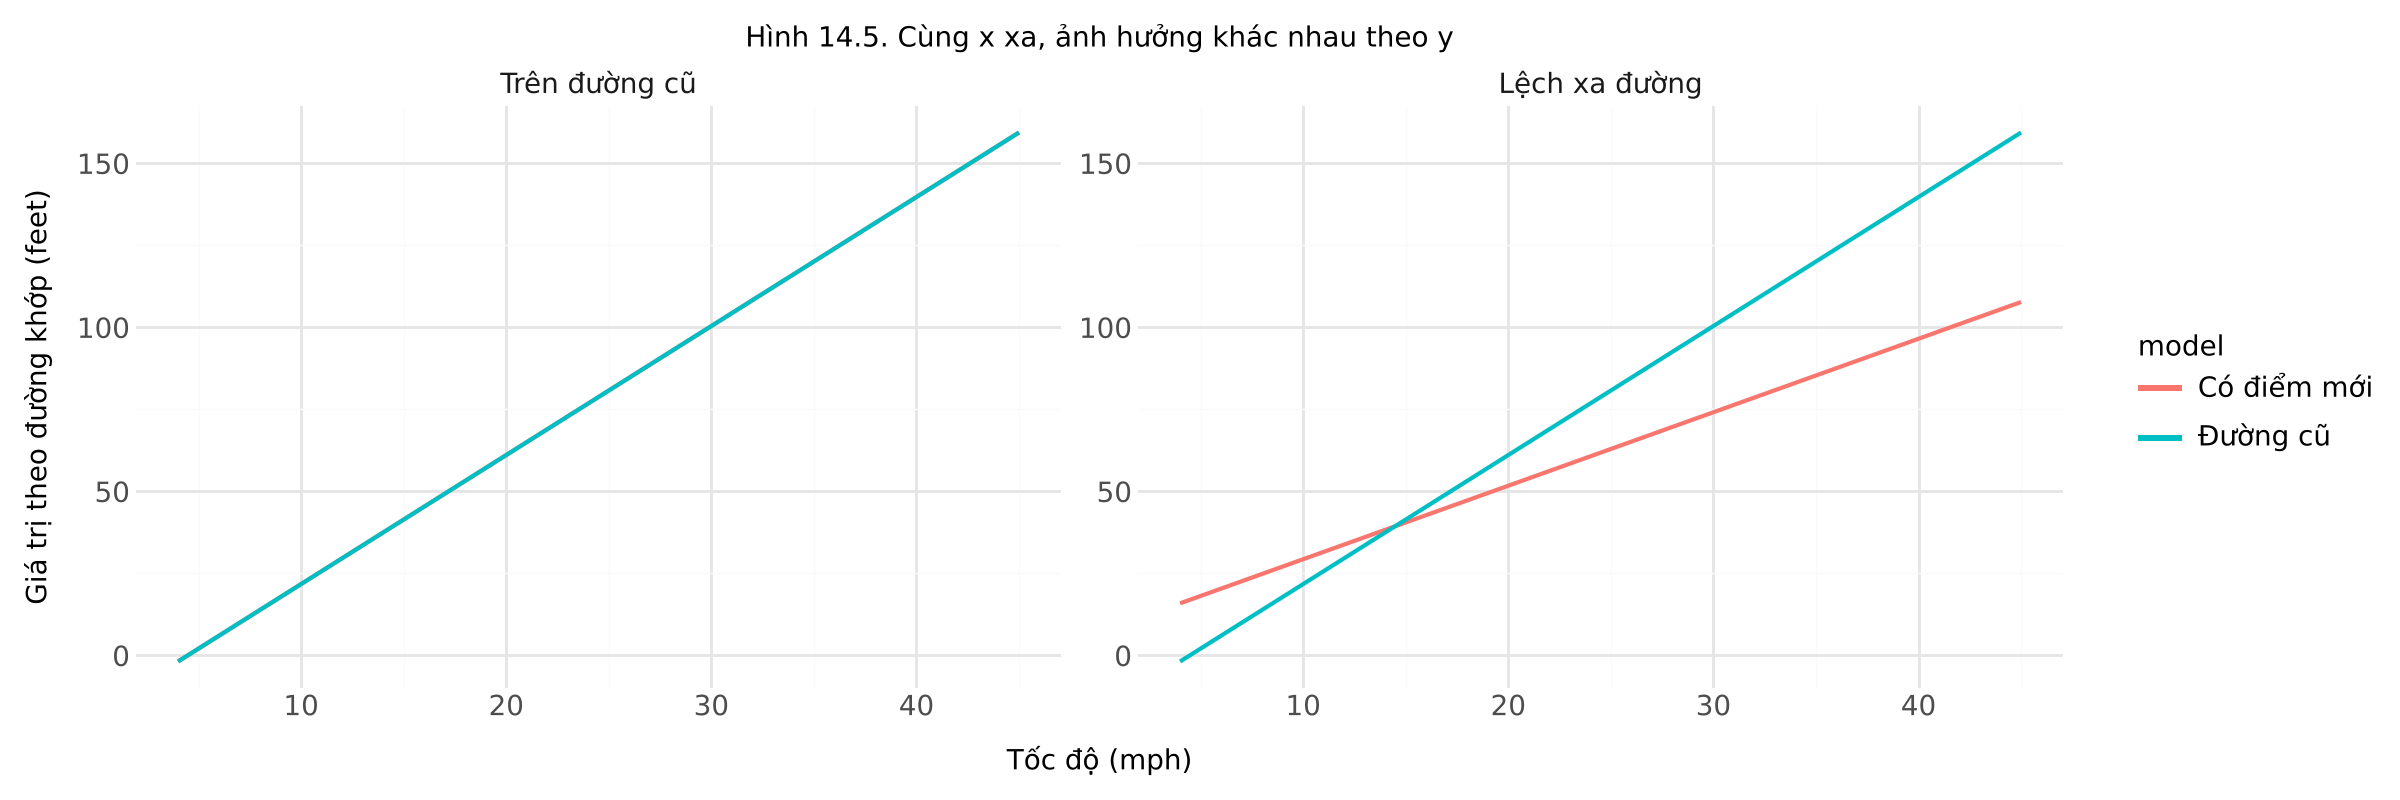

In [13]:
plot_data = sensitivity_lines.copy()
plot_data['scenario'] = pd.Categorical(plot_data['scenario'], categories=list(pd.unique(plot_data['scenario'])), ordered=True)
p = (ggplot(plot_data, aes(x='speed', y='prediction', color='model'))
     + geom_line(size=0.85)
     + facet_wrap('~scenario', scales='free', ncol=3)
     + labs(title='Hình 14.5. Cùng x xa, ảnh hưởng khác nhau theo y', x='Tốc độ (mph)', y='Giá trị theo đường khớp (feet)')
     + theme_minimal()
     + theme(figure_size=(12, max(4, 3.4*int(np.ceil(sensitivity_lines['scenario'].nunique()/3)))), text=element_text(size=10)))
display(p)

**Kết quả.** Leverage của điểm mới là 0,397 ở **cả hai** kịch bản (leverage chỉ phụ thuộc $x$; trung bình leverage của 51 điểm chỉ là $2/51\approx0{,}04$). Hệ số góc: giữ nguyên 3,93 ở kịch bản 1, giảm còn 2,24 ở kịch bản 2. Một điểm duy nhất làm hệ số góc giảm gần một nửa.

Điểm $x=45$ là kịch bản giả định để thử độ nhạy, không phải lần thử xe thật.

**Thử đổi.** Trong ô trên, sửa `old_prediction-130` thành `old_prediction-75`, `old_prediction`, `old_prediction+75` rồi chạy lại ô tính và ô hình. Trước khi chạy, đoán hệ số góc mới tăng hay giảm so với 3,93.

<a id="muc-5"></a>

## 5. Nhiều biến dự đoán và VIF

### Thêm biến dự đoán

Ở Tuần 04, ta đã dựng mô hình nhiều biến $\hat y=b_0+b_1x_1+\cdots+b_px_p$ và diễn giải mỗi hệ số "khi giữ các biến khác cố định". Lợi ích: tách được đóng góp của từng biến. Ví dụ trong nhà máy, `air_flow` và `water_temp` cùng tăng khi vận hành mạnh; nếu chỉ hồi quy theo `air_flow`, hệ số của nó gộp cả phần "ăn theo" của nhiệt độ nước.

"Giữ biến khác cố định" mô tả một phép so sánh **trong mô hình**, không phải một can thiệp thật chỉ thay đổi một biến (Tuần 12).

### Đa cộng tuyến

Khi các biến dự đoán **tương quan mạnh với nhau** (`air_flow` và `water_temp` có tương quan 0,78), mô hình vẫn khớp được và $\hat y$ vẫn có thể dự đoán tốt, nhưng **từng hệ số riêng lẻ kém ổn định**: sai số chuẩn của hệ số tăng mạnh, nên khó tin khi diễn giải từng hệ số tách biệt. Lý do trực quan: nếu hai biến luôn đi cùng nhau, dữ liệu không cho biết phần thay đổi của $y$ là do biến nào.

### Hệ số phóng đại phương sai

Hồi quy biến $x_j$ theo **tất cả các biến dự đoán còn lại** (có hệ số chặn); gọi $R_j^2$ là hệ số xác định của hồi quy phụ đó. Khi đó
$$\text{VIF}_j=\frac1{1-R_j^2}.$$
Đọc là: $R_j^2$ càng gần 1 ($x_j$ càng được các biến khác giải thích tốt) thì VIF càng lớn.

- VIF là hệ số phóng đại **phương sai** của $b_j$, so với khi $x_j$ không tương quan với các biến khác.
- **Sai số chuẩn** của $b_j$ được nhân với $\sqrt{\text{VIF}_j}$, không phải với VIF. Ví dụ VIF $=4$ làm SE tăng gấp 2.
- Quy tắc kinh nghiệm: VIF $>5$ đáng xem lại. Đây là ngưỡng cảnh báo, không phải kiểm định.
- Khi tính bằng `variance_inflation_factor` của statsmodels, **phải thêm cột hằng số** (`sm.add_constant`) vào ma trận biến. Thiếu hằng số, hồi quy phụ không có hệ số chặn và VIF có thể sai lệch tới hàng chục lần.
<details><summary><b>Vì sao?</b> VIF phóng đại phương sai của hệ số</summary>

Trong hồi quy nhiều biến với sai số độc lập, phương sai không đổi $\sigma^2$, có thể chứng minh
$$\mathrm{Var}(b_j)=\frac{\sigma^2}{S_{jj}}\cdot\frac1{1-R_j^2},\qquad S_{jj}=\sum_i(x_{ij}-\bar x_j)^2.$$
Thừa số đầu $\sigma^2/S_{jj}$ đúng bằng phương sai của hệ số góc nếu $x_j$ là biến duy nhất (mục 2, bình phương lên). Thừa số thứ hai là VIF.

Ý nghĩa: chỉ phần biến thiên của $x_j$ **không** trùng với các biến khác, tức $(1-R_j^2)S_{jj}$, mới giúp ước lượng $b_j$. Khi $R_j^2\to1$, phần đó tiến về 0 và $\mathrm{Var}(b_j)\to\infty$.

</details>

### Bài tập 4 — Tính VIF từ R²j

Hồi quy mỗi biến dự đoán theo các biến còn lại (dữ liệu `stackloss`) cho:

| Biến | $R_j^2$ |
|---|---|
| air_flow | 0,65 |
| water_temp | 0,60 |
| acid_conc | 0,25 |

Tính $\text{VIF}_j=1/(1-R_j^2)$ cho mỗi biến. So với ngưỡng 5, có biến nào đáng lo về đa cộng tuyến không?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

$$\text{VIF}_{\text{air\_flow}}=\frac1{0{,}35}\approx2{,}86,\qquad \text{VIF}_{\text{water\_temp}}=\frac1{0{,}40}=2{,}50,\qquad \text{VIF}_{\text{acid\_conc}}=\frac1{0{,}75}\approx1{,}33.$$
Cả ba dưới 5: chưa có biến nào đáng lo nghiêm trọng. `air_flow` và `water_temp` có VIF cao hơn vì hai biến này tương quan với nhau (cùng phản ánh mức vận hành nhà máy).

Theo cách đọc ở trên: SE của hệ số `air_flow` lớn gấp khoảng $\sqrt{2{,}86}\approx1{,}69$ lần so với khi nó không tương quan với hai biến kia.

Các $R_j^2$ là số đã làm tròn của đề; VIF tính trực tiếp từ 21 quan sát (ô dưới) hơi khác: 2,91; 2,57; 1,33.

</details>

Ô dưới tính VIF trực tiếp từ dữ liệu, cột `SE_factor` $=\sqrt{\text{VIF}}$, rồi in output đầy đủ của mô hình 3 biến.

`variance_inflation_factor(X, j+1)`: `X` là ma trận đã thêm cột hằng số ở vị trí 0, nên biến thứ $j$ nằm ở cột $j+1$.

In [14]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
predictors=['air_flow','water_temp','acid_conc']
full=smf.ols('stack_loss ~ air_flow + water_temp + acid_conc',stack).fit()
X=sm.add_constant(stack[predictors])
vif=pd.DataFrame({'variable':predictors,'VIF':[variance_inflation_factor(X.to_numpy(),j+1) for j in range(3)]})
vif['SE_factor']=np.sqrt(vif.VIF)
display(vif)
display(pd.DataFrame({'r2_given':[.65,.60,.25],'VIF':1/(1-np.array([.65,.60,.25]))}))
print(full.summary())
stack_diagnostic=pd.DataFrame({'fitted':full.fittedvalues,'residual':full.resid})

,variable,VIF,SE_factor
0,air_flow,2.90648,1.70484
1,water_temp,2.57263,1.60394
2,acid_conc,1.33359,1.15481


,r2_given,VIF
0,0.65,2.85714
1,0.60,2.50000
2,0.25,1.33333


                            OLS Regression Results                            
Dep. Variable:             stack_loss   R-squared:                       0.914
Model:                            OLS   Adj. R-squared:                  0.898
Method:                 Least Squares   F-statistic:                     59.90
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           3.02e-09
Time:                        02:34:31   Log-Likelihood:                -52.288
No. Observations:                  21   AIC:                             112.6
Df Residuals:                      17   BIC:                             116.8
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -39.9197     11.896     -3.356      0.0

**Đọc output.** Trong bảng `coef`: `air_flow` có hệ số 0,716 (p < 0,001), `water_temp` 1,295 (p = 0,003), `acid_conc` −0,152 (p = 0,344). $R^2=0{,}914$, $R^2_{adj}=0{,}898$. Dòng ghi chú về "condition number lớn" của statsmodels là một cảnh báo khác về số học (thang các biến khác nhau); VIF đã cho thấy đa cộng tuyến ở mức vừa phải.

<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(stack_diagnostic, aes(...))` lấy bảng `stack_diagnostic`; trong `aes`, trục ngang là cột `fitted`, trục đứng là cột `residual`. `geom_point()` vẽ mỗi dòng của bảng thành một chấm.

**Đọc hình.** Chỉ 21 điểm, rải quanh 0 trong khoảng ±7. Không thấy hình cong hay loa kèn rõ, nhưng với ít điểm như vậy, đồ thị khó phát hiện vi phạm nhẹ.

<!-- branch-plot-instructions: end -->

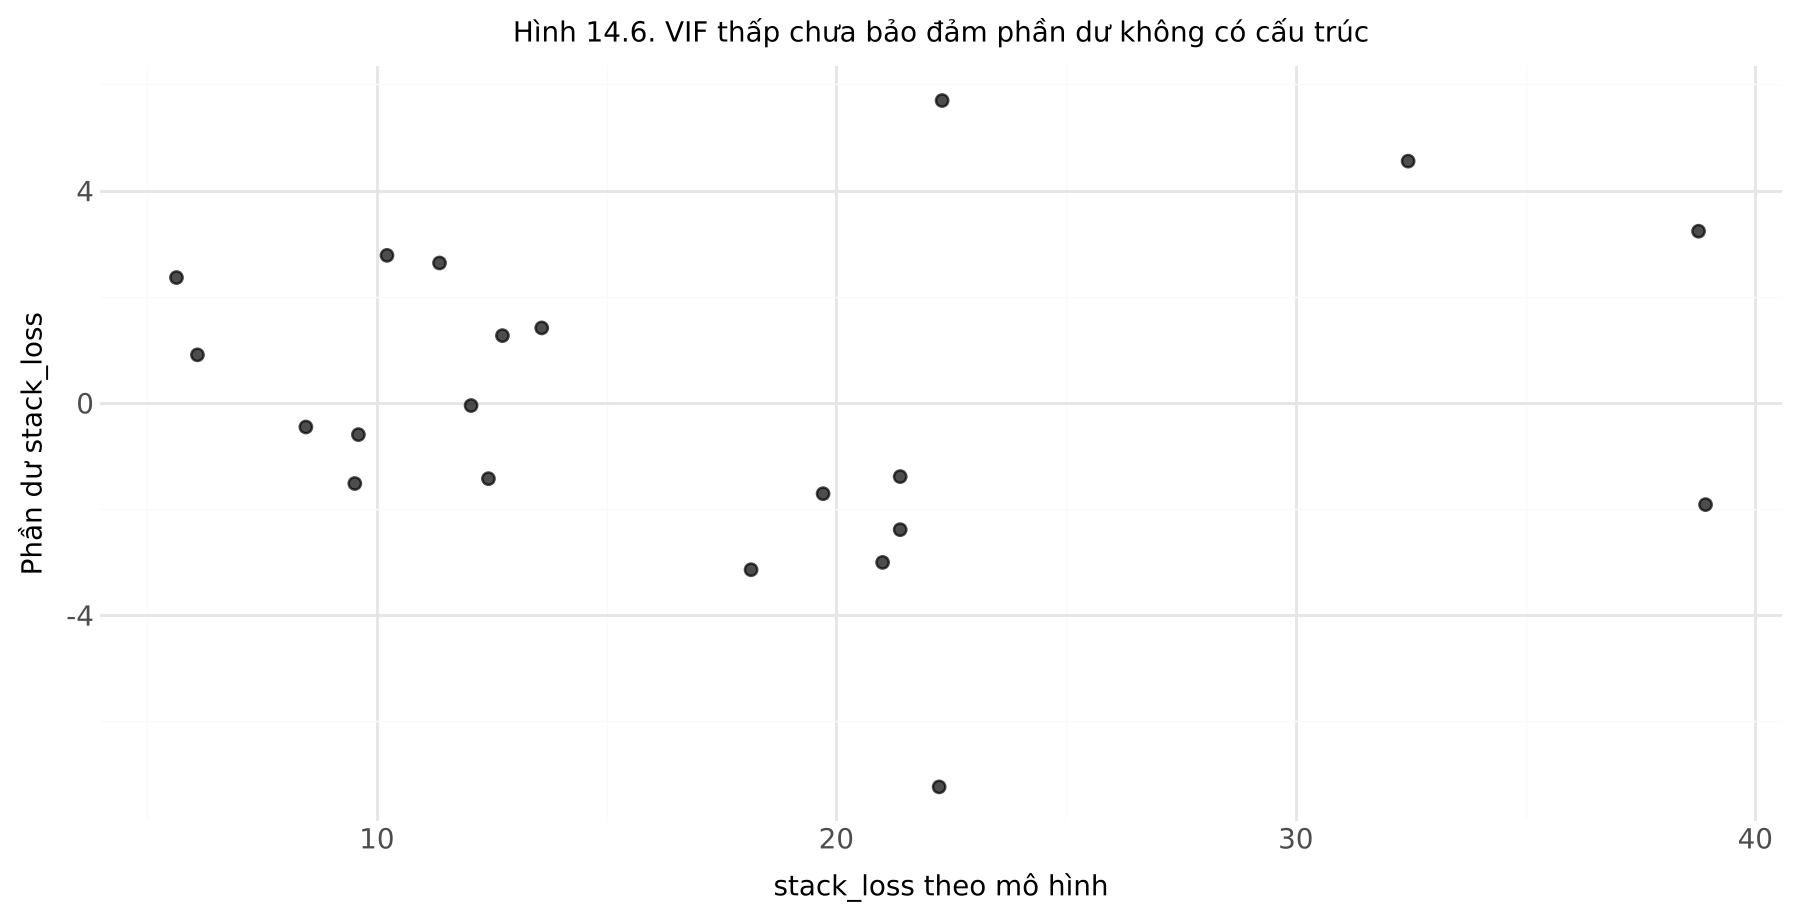

In [15]:
p = (ggplot(stack_diagnostic, aes(x='fitted', y='residual'))
     + geom_point(alpha=0.7, size=2)
     + labs(title='Hình 14.6. VIF thấp chưa bảo đảm phần dư không có cấu trúc', x='stack_loss theo mô hình', y='Phần dư stack_loss')
     + theme_minimal()
     + theme(figure_size=(9, 4.6), text=element_text(size=10)))
display(p)

Bốn điều kiện ở mục 4 vẫn áp dụng cho hồi quy nhiều biến. Điều kiện tuyến tính cần kiểm tra **cho từng biến dự đoán**: VIF thấp không có nghĩa mô hình đúng dạng hàm. Nên vẽ thêm phần dư theo từng biến `air_flow`, `water_temp`, `acid_conc`, và theo thứ tự đo nếu có.

<a id="muc-6"></a>

## 6. Chọn biến: phạt độ phức tạp chưa thay được đánh giá ngoài mẫu

### Mô hình đầy đủ chưa chắc tốt nhất

Mô hình dùng mọi biến sẵn có gọi là **mô hình đầy đủ**. Thêm biến không thật sự liên quan có thể làm mô hình kém tin cậy khi dự đoán dữ liệu mới, dù $R^2$ vẫn tăng. Vậy nên giữ hay bỏ một biến?

### $R^2$ hiệu chỉnh

$$R^2_{adj}=1-\frac{\text{RSS}/(n-p-1)}{\text{TSS}/(n-1)}.$$
Đọc là: thay vì so RSS với TSS, so **phương sai ước lượng** của sai số với phương sai của $y$; mỗi biến thêm vào làm mẫu số $n-p-1$ nhỏ đi, nên RSS phải giảm đủ nhiều mới bù được.

- Thêm biến **luôn** làm $R^2$ tăng hoặc giữ nguyên; $R^2_{adj}$ có thể **giảm** nếu biến mới không cải thiện đủ.
- So sánh phải trên cùng biến kết quả và cùng các dòng dữ liệu.
- `stackloss` (3 biến, $n=21$): $R^2=0{,}914$, $R^2_{adj}=1-(1-0{,}914)\times\frac{20}{17}\approx0{,}898$.

### Loại trừ lùi và chọn tiến

**Loại trừ lùi** (backward elimination):

1. Bắt đầu từ mô hình đầy đủ.
2. Ở mỗi bước, thử bỏ **từng** biến một; chọn bỏ biến làm $R^2_{adj}$ tăng nhiều nhất.
3. Dừng khi bỏ biến nào cũng làm $R^2_{adj}$ giảm.

**Chọn tiến** (forward selection): bắt đầu từ mô hình không có biến nào; mỗi bước thêm biến làm $R^2_{adj}$ tăng nhiều nhất; dừng khi thêm biến nào cũng không cải thiện. Hai cách đôi khi cho mô hình khác nhau; khi đó slide đề nghị chọn mô hình có $R^2_{adj}$ cao hơn.

**Dùng giá trị p.** Mỗi bước bỏ biến có giá trị p lớn nhất; dừng khi giá trị p lớn nhất còn lại nhỏ hơn mức ý nghĩa. Slide: $R^2_{adj}$ hợp khi mục tiêu là dự đoán; giá trị p hợp khi mục tiêu là xem biến nào có ý nghĩa, hoặc muốn mô hình đơn giản.

**Ba lưu ý.** Cả hai cách đều là thủ tục "tham lam", không bảo đảm tìm được tập biến tốt nhất trong mọi tập con. $R^2_{adj}$ vẫn là tiêu chí **trong mẫu**. Và nếu dùng giá trị p để chọn biến rồi báo cáo giá trị p của mô hình cuối như thể mô hình được định trước, bằng chứng bị đánh giá quá cao. Với mục tiêu dự đoán, cần xác nhận bằng dữ liệu kiểm tra (Tuần 15).

### Ví dụ 2 — Loại trừ lùi trên dữ liệu stackloss

Mô hình đầy đủ (`air_flow + water_temp + acid_conc`) có $R^2_{adj}=0{,}898$. Bỏ từng biến:

| Bỏ biến | $R^2_{adj}$ sau khi bỏ |
|---|---|
| air_flow | 0,745 |
| water_temp | 0,834 |
| acid_conc | 0,899 |

Nên bỏ biến nào? Bước tiếp theo kiểm tra thế nào? Mô hình cuối là gì?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Bước 1.* Bỏ `acid_conc` cho $R^2_{adj}=0{,}899>0{,}898$, cao nhất trong ba lựa chọn và cao hơn mô hình đầy đủ: **bỏ** `acid_conc`.

*Bước 2.* Từ mô hình `air_flow + water_temp`, thử bỏ tiếp từng biến: bỏ `air_flow` còn 0,754, bỏ `water_temp` còn 0,838. Cả hai đều làm $R^2_{adj}$ giảm so với 0,899: **dừng**.

*Mô hình cuối:* `stack_loss ~ air_flow + water_temp`, $R^2_{adj}=0{,}899$.

Đối chiếu giá trị p: trong mô hình đầy đủ, `acid_conc` có giá trị p lớn nhất (0,344), nên cách dùng giá trị p cũng bỏ nó trước; hai cách cho cùng kết quả ở đây.

Đây là lựa chọn theo tiêu chí trong mẫu; chưa chứng minh mô hình hai biến dự đoán tốt nhất trên dữ liệu mới.

</details>

Ô dưới chạy cả hai thủ tục. Vòng `while` của loại trừ lùi: với mỗi biến đang giữ, khớp mô hình không có biến đó, ghi $R^2_{adj}$; chọn lần bỏ tốt nhất; nếu nó không cải thiện thì `break`. Chọn tiến làm ngược lại, bắt đầu từ mô hình chỉ có hệ số chặn (`stack_loss ~ 1`). `max(candidates, key=lambda item: item[0])` lấy ứng viên có $R^2_{adj}$ lớn nhất.

In [16]:
backward_vars=predictors.copy(); backward_log=[]
while backward_vars:
    current=smf.ols('stack_loss ~ '+' + '.join(backward_vars),stack).fit()
    candidates=[]
    for variable in backward_vars:
        remain=[v for v in backward_vars if v!=variable]
        candidate=smf.ols('stack_loss ~ '+(' + '.join(remain) if remain else '1'),stack).fit()
        candidates.append((candidate.rsquared_adj,variable,remain))
        backward_log.append([','.join(backward_vars),variable,candidate.rsquared_adj])
    score,variable,remain=max(candidates,key=lambda item:item[0])
    if score<=current.rsquared_adj+1e-12:break
    backward_vars=remain
display(pd.DataFrame(backward_log,columns=['Đang giữ','Thử bỏ','R²adj sau bỏ']))
print('Lùi, giữ:',backward_vars)
forward_vars=[]; forward_score=smf.ols('stack_loss ~ 1',stack).fit().rsquared_adj
while len(forward_vars)<len(predictors):
    candidates=[]
    for variable in predictors:
        if variable in forward_vars:continue
        candidate=smf.ols('stack_loss ~ '+' + '.join(forward_vars+[variable]),stack).fit()
        candidates.append((candidate.rsquared_adj,variable))
    score,variable=max(candidates,key=lambda item:item[0])
    if score<=forward_score+1e-12:break
    forward_vars.append(variable);forward_score=score
print('Tiến, giữ:',forward_vars,'R²adj:',forward_score)

,Đang giữ,Thử bỏ,R²adj sau bỏ
0,"air_flow,water_temp,acid_conc",air_flow,0.74491
1,"air_flow,water_temp,acid_conc",water_temp,0.83400
2,"air_flow,water_temp,acid_conc",acid_conc,0.89862
3,"air_flow,water_temp",air_flow,0.75422
4,"air_flow,water_temp",water_temp,0.83766


Lùi, giữ: ['air_flow', 'water_temp']
Tiến, giữ: ['air_flow', 'water_temp'] R²adj: 0.8986232692781059


Cả hai thủ tục dừng ở `air_flow + water_temp`. Bỏ `acid_conc` chỉ tăng $R^2_{adj}$ từ 0,8983 lên 0,8986, khoảng ba phần mười nghìn. Chênh lệch nhỏ như vậy có thể không bền khi có dữ liệu mới; đừng chọn mô hình chỉ dựa vào thứ hạng của những con số gần nhau như thế.

### Bài tập 5 — Thêm biến vào mô hình

Mô hình C (`y ~ x1 + x2`): $R^2=0{,}812$, $R^2_{adj}=0{,}799$. Mô hình D (`y ~ x1 + x2 + x3`): $R^2=0{,}818$, $R^2_{adj}=0{,}793$. Có nên thêm $x_3$ không? Vì sao $R^2$ tăng mà $R^2_{adj}$ lại giảm?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Theo $R^2_{adj}$:* không thêm, vì $R^2_{adj}$ giảm từ 0,799 xuống 0,793.

*Vì sao đi ngược nhau?* $R^2$ tăng (0,812 → 0,818) vì thêm biến hầu như luôn làm RSS giảm một chút: mô hình D chứa mô hình C (đặt hệ số $x_3$ bằng 0 là được C), nên khớp ít nhất bằng C. $R^2_{adj}$ thì phạt việc mất thêm một bậc tự do; mức giảm RSS nhờ $x_3$ không đủ bù phần phạt.

Kết luận đúng mức: theo tiêu chí này, $x_3$ không giúp ích cho dự đoán trong mẫu. Hai con số chưa đủ để nói $x_3$ vô dụng cho mọi mục tiêu.

</details>

<a id="muc-7"></a>

## 7. Tương tác cho độ dốc khác nhau

### Biến giả và giả định cùng độ dốc

Biến phân loại (loại vật liệu A/B, giống lúa...) được đưa vào mô hình bằng **biến giả** 0/1 so với một nhóm tham chiếu (Tuần 04). Với $A$ là nhóm tham chiếu và $I(B)=1$ nếu đơn vị thuộc nhóm B:
$$\hat y=b_0+b_1x+b_2\, I(B).$$
Nhóm A: $\hat y=b_0+b_1x$. Nhóm B: $\hat y=(b_0+b_2)+b_1x$. Hai đường **song song**: cùng độ dốc $b_1$, chỉ khác hệ số chặn. Đây là **mô hình cộng tính**.

### Thêm tương tác

Nếu tác động của $x$ lên $y$ khác nhau giữa các nhóm, thêm số hạng tích:
$$\hat y=b_0+b_1x+b_2\, I(B)+b_3\, x\, I(B).$$

| Nhóm | Hệ số chặn | Độ dốc |
|---|---|---|
| A | $b_0$ | $b_1$ |
| B | $b_0+b_2$ | $b_1+b_3$ |

- $b_3$ là **chênh lệch độ dốc** giữa B và A.
- Chênh lệch B − A tại một giá trị $x$ là $b_2+b_3x$: nó thay đổi theo $x$. Hệ số $b_2$ chỉ là chênh lệch **tại $x=0$**; nếu $x=0$ không có ý nghĩa thực tế (độ dày 0), có thể dịch gốc $x$ về một giá trị hợp lý rồi diễn giải lại.

Trong statsmodels: `độ_bền ~ độ_dày + C(loại)` là mô hình cộng tính; `độ_bền ~ độ_dày * C(loại)` gồm cả hai hiệu ứng chính và tích tương tác. Trong output, `C(type)[T.B]` là $b_2$ (chênh lệch mức nền) và `thickness: C(type)[T.B]` là $b_3$ (chênh lệch độ dốc).

### Khi nào giữ tương tác?

Thêm tương tác luôn làm $R^2$ tăng hoặc giữ nguyên, nên $R^2$ tăng **không** tự là bằng chứng. Chỉ giữ khi (1) hệ số tương tác có ý nghĩa thống kê hoặc $R^2_{adj}$ tăng rõ, hoặc (2) có lý do khoa học, kỹ thuật vững để tin độ dốc thật sự khác nhau. Ví dụ `năng_suất ~ lượng_phân_bón * C(giống_lúa)`: chỉ giữ tương tác nếu có bằng chứng hiệu quả phân bón thật sự khác nhau giữa các giống.

### Ví dụ 3 — Độ bền theo độ dày của hai loại vật liệu

Khớp hai mô hình trên cùng dữ liệu độ bền vật liệu. Cộng tính: $R^2=0{,}909$, $R^2_{adj}=0{,}883$. Có tương tác: $R^2=0{,}998$, $R^2_{adj}=0{,}998$, giá trị p của hệ số tương tác $<0{,}0001$. Nên chọn mô hình nào? Giải thích.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

Chọn **mô hình có tương tác**. $R^2_{adj}$ tăng mạnh (0,883 → 0,998), và hệ số tương tác có giá trị p rất nhỏ: có bằng chứng rõ rằng độ dốc (độ bền tăng thêm khi dày thêm một đơn vị) khác nhau giữa hai loại vật liệu.

Mô hình cộng tính buộc hai đường song song, nên nó dự đoán sai có hệ thống: quá cao cho một loại ở độ dày lớn, quá thấp cho loại kia.

Slide không kèm dữ liệu gốc; ô dưới **mô phỏng** một bộ dữ liệu cùng hình dạng (vật liệu A dốc 0,6, B dốc 1,7), không cố ép trùng đúng các chỉ số của slide.

</details>

In [17]:
r_material=np.random.default_rng(42)
material=pd.DataFrame({'thickness':np.tile(np.linspace(1,10,12),2),'type':np.repeat(['A','B'],12)})
material['strength']=2+np.where(material.type=='A',.6,1.7)*material.thickness+r_material.normal(0,.25,len(material))
additive=smf.ols('strength ~ thickness + C(type)',material).fit()
interacting=smf.ols('strength ~ thickness * C(type)',material).fit()
grid_material=pd.DataFrame({'thickness':np.tile(np.linspace(1,10,100),2),'type':np.repeat(['A','B'],100)})
interaction_lines=pd.concat([grid_material.assign(prediction=model.predict(grid_material),model=name)
    for name,model in [('Cộng tính',additive),('Có tương tác',interacting)]])
display(pd.DataFrame({'model':['Cộng tính','Tương tác'],'R²':[additive.rsquared,interacting.rsquared],
    'R²adj':[additive.rsquared_adj,interacting.rsquared_adj]}))
print('Hệ số mô hình tương tác:',interacting.params.to_dict())

,model,R²,R²adj
0,Cộng tính,0.89392,0.88382
1,Tương tác,0.99817,0.99789


Hệ số mô hình tương tác: {'Intercept': 1.8893924068019199, 'C(type)[T.B]': 0.1697084625666938, 'thickness': 0.6136766715899276, 'thickness:C(type)[T.B]': 1.0802826449874783}


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(interaction_lines, aes(...))` lấy bảng `interaction_lines`; trong `aes`, trục ngang là cột `thickness`, trục đứng là cột `prediction`. `color='type'` cho mỗi giá trị của cột `type` một màu riêng. `geom_line()` nối các điểm theo thứ tự tăng dần của trục ngang. `facet_wrap('~model', scales='free')` vẽ mỗi giá trị của `model` vào một ô riêng; `scales='free'` cho mỗi ô thang trục riêng, nên so các ô bằng số ghi trên trục, không bằng độ cao trên màn hình.

**Đọc hình.** Ô “Cộng tính”: hai đường song song, cách nhau một khoảng cố định. Ô “Có tương tác”: hai đường xuất phát gần nhau ở độ dày 1 rồi tách xa dần, vì B dốc hơn A nhiều. Cùng dữ liệu, chỉ khác mô hình.

<!-- branch-plot-instructions: end -->

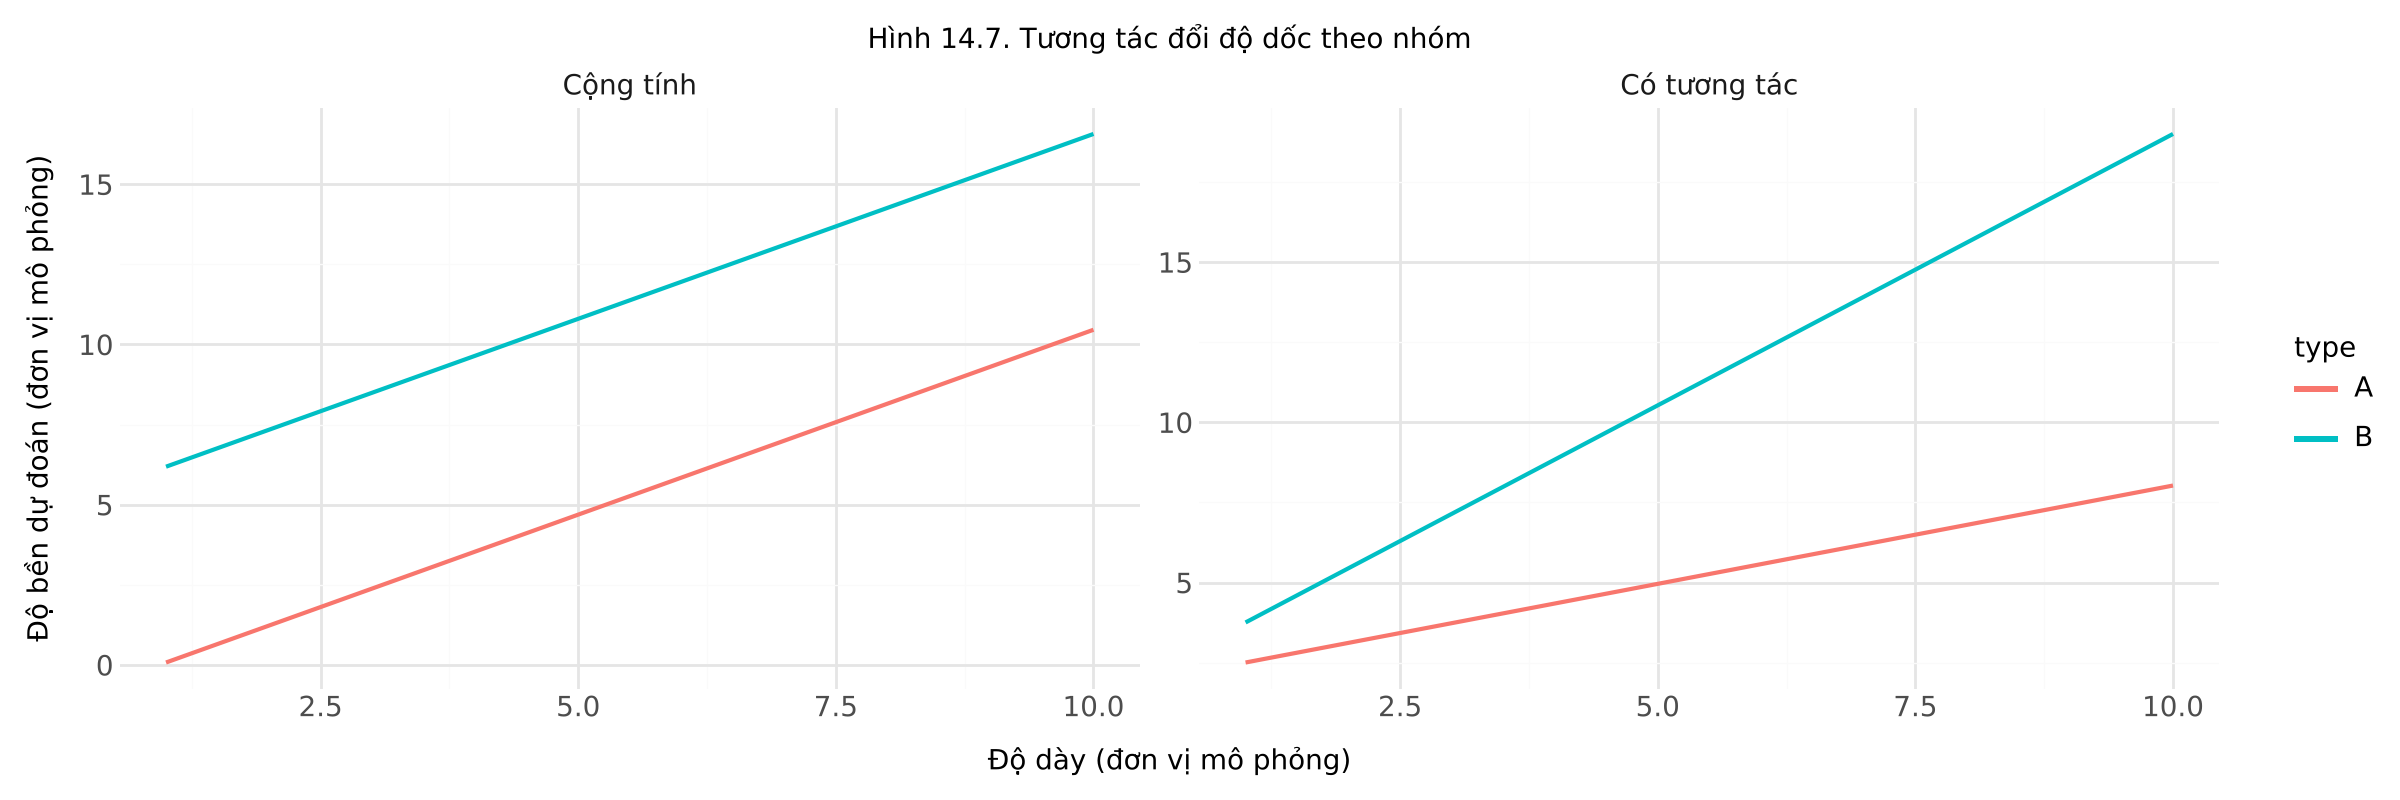

In [18]:
plot_data = interaction_lines.copy()
plot_data['model'] = pd.Categorical(plot_data['model'], categories=list(pd.unique(plot_data['model'])), ordered=True)
p = (ggplot(plot_data, aes(x='thickness', y='prediction', color='type'))
     + geom_line(size=0.85)
     + facet_wrap('~model', scales='free', ncol=3)
     + labs(title='Hình 14.7. Tương tác đổi độ dốc theo nhóm', x='Độ dày (đơn vị mô phỏng)', y='Độ bền dự đoán (đơn vị mô phỏng)')
     + theme_minimal()
     + theme(figure_size=(12, max(4, 3.4*int(np.ceil(interaction_lines['model'].nunique()/3)))), text=element_text(size=10)))
display(p)

**Đọc hệ số** của mô hình tương tác (dòng in cuối): `thickness` $\approx0{,}61$ là độ dốc của A; `thickness: C(type)[T.B]` $\approx1{,}08$ là chênh lệch độ dốc, nên độ dốc của B là $0{,}61+1{,}08\approx1{,}69$. `C(type)[T.B]` $\approx0{,}17$ là chênh lệch tại độ dày 0, nhỏ vì hai đường gần nhau ở gốc. Chênh lệch B − A ở độ dày 10 là $0{,}17+1{,}08\times10\approx11$.

### Bài tập 6 — Đánh giá số hạng tương tác

Mô hình A (cộng tính): $R^2=0{,}85$. Mô hình B (có tương tác): $R^2=0{,}86$, giá trị p của hệ số tương tác $=0{,}42$. Có nên giữ tương tác chỉ vì $R^2$ tăng không?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

Không. $R^2$ chỉ tăng 0,01, đúng kiểu tăng nhẹ luôn xảy ra khi thêm số hạng. Giá trị p 0,42 cho thấy không đủ bằng chứng độ dốc khác nhau giữa các nhóm. Theo dữ kiện của bài, nên dùng mô hình cộng tính, đơn giản hơn.

Kết luận này không có nghĩa "chắc chắn độ dốc bằng nhau". Nếu có lý do khoa học mạnh để tin độ dốc khác nhau, cần thêm dữ liệu hoặc một kiểm tra khác, chứ không dựa vào chênh lệch $R^2$ 0,01.

</details>

<a id="muc-8"></a>

## 8. Đọc output và viết kết luận có giới hạn

### Quy trình 5 bước đọc một output hồi quy để dự đoán

1. **Hệ số góc $b_j$**: dấu và độ lớn cho biết xu hướng liên hệ; với mô hình nhiều biến, nhớ điều kiện "giữ các biến khác cố định".
2. **Giá trị p của $b_j$**: có đủ bằng chứng thống kê cho liên hệ không (mục 2).
3. **$R^2_{adj}$ và RSE**: mô hình giải thích được bao nhiêu, sai số dự đoán cỡ nào (mục 3, 6).
4. **VIF và biểu đồ phần dư**: kiểm tra trước khi tin từng hệ số riêng lẻ (mục 4, 5).
5. **Luôn kèm cảnh báo**: không ngoại suy xa phạm vi dữ liệu; liên hệ không phải nhân quả, trừ khi có thiết kế thí nghiệm hay luận cứ khoa học hỗ trợ.

Kết luận gọn nhất gồm **ba câu**: xu hướng, mức giải thích (hay đánh giá), cảnh báo.

### Ví dụ 4 — Tỉ lệ lỗi theo nhiệt độ xử lý

Mô hình `tỉ_lệ_lỗi ~ nhiệt_độ_xử_lý` cho $b_1=-0{,}42$, giá trị p $<0{,}01$, $R^2=0{,}58$. Viết ba câu kết luận: xu hướng, mức giải thích, cảnh báo.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Xu hướng.* "Khi nhiệt độ xử lý cao hơn 1°C, tỉ lệ lỗi sản phẩm dự đoán thấp hơn trung bình 0,42 **điểm phần trăm**." (Tỉ lệ lỗi đo bằng %, nên đơn vị của hệ số là điểm phần trăm trên °C, không phải "giảm 0,42%".)

*Mức giải thích.* "Mô hình giải thích được 58% biến thiên tỉ lệ lỗi trong dữ liệu bằng nhiệt độ xử lý."

*Cảnh báo.* "Không áp dụng dự đoán ngoài phạm vi nhiệt độ đã thử; cần kiểm tra thêm nhiệt độ có thật sự là nguyên nhân hay chỉ đi cùng một yếu tố vận hành khác."

Giá trị p $<0{,}01$ có thể đưa vào câu đầu: "liên hệ này có ý nghĩa thống kê ở mức 1%".

</details>

### Bài tập 7 — Tổng hợp trên lớp

(1) Với đường hồi quy của `cars`, tính dự đoán tại $x=20$ và $x=30$ mph; so sánh và nhận xét về ngoại suy. (2) Dùng output `stackloss` có VIF và $R^2_{adj}$ đã chạy ở trên: quyết định nên giữ biến nào, có nên thêm tương tác không. (3) Viết đúng 3 câu kết luận theo quy trình 5 bước.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*(1)* Dùng hệ số đầy đủ: $\hat y(20)\approx61{,}07$ feet, $\hat y(30)\approx100{,}39$ feet. Dùng đường làm tròn $-17{,}58+3{,}93x$: 61,02 và 100,32 feet. Dữ liệu chỉ có tốc độ 4–25 mph, nên 20 mph là **nội suy**, còn 30 mph là **ngoại suy**: không có dữ liệu nào kiểm chứng đường thẳng còn đúng ở đó (thực tế quãng đường dừng tăng nhanh hơn tuyến tính theo tốc độ).

*(2)* VIF đều dưới 5; loại trừ lùi và chọn tiến đều giữ `air_flow + water_temp`. Chưa có dữ kiện (lý do kỹ thuật hay kết quả kiểm định) để thêm tương tác.

*(3)* Ví dụ: “Trong dữ liệu 21 quan sát, lưu lượng khí và nhiệt độ nước cao hơn đi cùng tỉ lệ thất thoát cao hơn, cả hai có ý nghĩa thống kê ở mức 1%. Mô hình hai biến có $R^2_{adj}\approx0{,}90$. Kết luận dựa trên 21 quan sát, các giả định của hồi quy và chưa được kiểm tra trên dữ liệu mới; không dùng ngoài phạm vi vận hành đã quan sát.”

</details>

### Bài tập 8 — Đọc nhanh output

Mô hình `y ~ x` cho $b_1=1{,}8$, $SE(b_1)=0{,}6$, giá trị p $=0{,}008$, $R^2=0{,}41$, RSE $=5{,}2$ (đơn vị của $y$). Viết 3 câu: (1) diễn giải hệ số góc, (2) kết luận về ý nghĩa thống kê của liên hệ, (3) diễn giải thực hành của RSE.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*(1)* Khi $x$ lớn hơn 1 đơn vị, $y$ dự đoán lớn hơn trung bình 1,8 đơn vị.

*(2)* Giá trị p $0{,}008<0{,}05$ (và $t=1{,}8/0{,}6=3$): có bằng chứng thống kê cho liên hệ tuyến tính khác 0, nếu các giả định của mô hình phù hợp.

*(3)* Sai số dự đoán điển hình cỡ 5,2 đơn vị của $y$, nên một dự đoán đơn lẻ vẫn có thể lệch đáng kể quanh đường hồi quy. Với $R^2=0{,}41$, phần lớn biến thiên của $y$ (59%) vẫn chưa được mô hình giải thích.

</details>

In [19]:
future=pd.DataFrame({'speed':[20,30]})
future['prediction']=car_model.predict(future)
future['outside_data']=~future.speed.between(cars.speed.min(),cars.speed.max())
display(future)
print('Miền tốc độ đã quan sát:',cars.speed.min(),cars.speed.max())

,speed,prediction,outside_data
0,20,61.06908,False
1,30,100.39317,True


Miền tốc độ đã quan sát: 4 25


## Tóm tắt và lỗi hay gặp

| Ý chính | Lỗi hay gặp |
|---|---|
| OLS và gradient descent tối ưu cùng một hàm mục tiêu nên cho cùng hệ số. | Tin hệ số khi thuật toán chưa hội tụ. |
| Kiểm định $\rho=0$ và $\beta_1=0$ trong hồi quy đơn cho cùng $T$, $df=n-2$. | Dùng số đã làm tròn rồi thắc mắc vì $T$ lệch. |
| $R^2$ (không đơn vị) và RSE (đơn vị của $y$) đo mức khớp **trong mẫu**. | Coi $R^2$ cao là dự đoán tốt trên dữ liệu mới. |
| Hồi quy đơn: $R^2=r^2$; RSS $=(1-r^2)$TSS. | Dùng $R^2$ so mô hình khác số biến. |
| Bốn điều kiện: tuyến tính, phần dư gần chuẩn, phương sai không đổi, độc lập (không đọc từ đồ thị). | Nghĩ đồ thị phần dư đẹp chứng minh độc lập. |
| Leverage do $x$; ảnh hưởng do cả $x$ và $y$. | Xóa điểm vì nó xa hay vì làm giá trị p xấu. |
| VIF $=1/(1-R_j^2)$ phóng đại **phương sai**; SE nhân $\sqrt{\text{VIF}}$. | Quên `add_constant` khi tính VIF. |
| $R^2_{adj}$ phạt số biến; loại trừ lùi/chọn tiến là thủ tục tham lam trong mẫu. | Báo giá trị p sau khi chọn biến như thể mô hình định trước. |
| Tương tác $b_3$ là chênh lệch độ dốc; chênh lệch nhóm $b_2+b_3x$ đổi theo $x$. | Giữ tương tác chỉ vì $R^2$ tăng nhẹ; đọc $b_2$ như chênh lệch ở mọi $x$. |

## Tự kiểm tra và nối sang buổi tiếp theo

1. Năm con số: giá trị p của hệ số nhỏ, $R^2$ cao, RSE nhỏ, VIF thấp, đồ thị phần dư đẹp. Mỗi con số cho biết điều gì? Con số nào trực tiếp đo sai số trên dữ liệu **chưa thấy**?
2. Một mô hình có $R^2=0{,}95$ trên 15 điểm với 10 biến dự đoán. Bạn nghi ngờ điều gì?
3. VIF của một biến là 9. Sai số chuẩn của hệ số đó lớn gấp bao nhiêu lần so với khi không có đa cộng tuyến?
4. Trong `cars`, vì sao dự đoán ở 30 mph đáng ngờ hơn ở 20 mph, dù cùng một đường?

<details><summary>Gợi ý đáp án</summary>

1. Giá trị p: bằng chứng hệ số khác 0. $R^2$: mức giải thích trong mẫu. RSE: độ lớn sai số điển hình trong mẫu. VIF: độ ổn định của từng hệ số. Phần dư: các điều kiện của mô hình. **Không con số nào** trực tiếp đo sai số trên dữ liệu chưa thấy; cần tập kiểm tra (Tuần 15).
2. Quá nhiều biến so với số điểm: $R^2$ gần như chắc chắn cao dù các biến vô dụng; $R^2_{adj}$ và đánh giá ngoài mẫu sẽ thấp hơn nhiều.
3. $\sqrt9=3$ lần.
4. 30 mph nằm ngoài khoảng 4–25 mph đã quan sát (ngoại suy); không có dữ liệu kiểm chứng đường thẳng còn đúng ở đó.

</details>

**Buổi sau.** Tuần 15 trả lời câu hỏi cuối cùng ở trên: tách riêng một **tập kiểm tra** để đo sai số trên dữ liệu chưa thấy, dùng **kiểm định chéo** trong tập huấn luyện để chọn độ phức tạp, và nhận diện **quá khớp**. Sau đó chuyển từ dự đoán số sang dự đoán **xác suất** và phân loại nhị phân bằng hồi quy logistic.

## Nguồn học liệu

- Slide của học phần: `week14.pdf`; số trang được ghi trong metadata `source_pages` của từng ô.
- Đề cương UET.MAT1052: mục và chuẩn đầu ra của tuần tương ứng.
- STAT 20 bản dịch tiếng Việt: mục 7.1–7.3; phần dư minh họa được dựng lại bằng Python. Các hình tham khảo được nhúng thẳng vào notebook.
- Dữ liệu và cách chuyển đổi: `datasets/W09_W15_SOURCE_MANIFEST.json` và [hướng dẫn tuần 09–15](./README_W09_W15.md). Dữ liệu OpenIntro lấy từ [kho dữ liệu của nhà xuất bản](https://www.openintro.org/data/).